# Прогнозирование цен на жилье в Турции

Цели проекта: Проанализировать рынок недвижимости Турции на основе датасета Zingat и подготовить данные для прогнозирования цен.

In [2]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from scipy.stats import skew

from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeRegressor


warnings.filterwarnings("ignore")

RANDOM_STATE = 42

In [48]:
df = pd.read_csv('real_estate_data.csv',low_memory=False)

In [77]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  object 
 2   sub_type           403487 non-null  object 
 3   start_date         403487 non-null  object 
 4   end_date           266298 non-null  object 
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  object 
 8   total_floor_count  375466 non-null  object 
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  object 
 11  size               257481 non-null  float64
 12  address            403487 non-null  object 
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  object 
 15  price              402772 non-null  float64
 16  pr

In [49]:
df.shape

(403487, 17)

Описание:
- Zingat — турецкая платформа по недвижимости
- Данные содержат объявления о продаже и аренде
- Датасет включает 403,487 объявлений
- Каждое объявление содержит информацию о:
  • Типе недвижимости (жильё, офис, коммерческое)
  • Местоположении (город, район, улица)
  • Характеристиках (площадь, комнаты, этаж, возраст)
  • Цене и валюте
  • Времени на рынке

1. КАТЕГОРИАЛЬНЫЕ (объектные) признаки:
   • тип           → тип недвижимости (Konut, Villa, Ofis...)
   • подтип        → подтип объекта (Daire, Müstakil Ev...)
   • тип_объявления → продажа или аренда (Satılık, Kiralık)
   • адрес         → полный адрес (город/район/улица)
   • город         → город
   • район         → район
   • улица         → улица
   • отопление     → тип отопления
   • валюта        → валюта цены

2. ЧИСЛОВЫЕ (количественные) признаки:
   • площадь       → площадь в м²
   • комнат_всего  → общее количество комнат
   • спальни       → количество спален
   • гостиные      → количество гостиных
   • всего_этажей  → количество этажей в здании
   • этаж          → этаж квартиры
   • возраст_здания → возраст здания
   • время_на_рынке → количество дней объявления на сайте

3. ЦЕЛЕВАЯ ПЕРЕМЕННАЯ:
   • цена_usd      → цена объекта в долларах США

In [79]:
df.describe()

,id,listing_type,tom,size,furnished,price
count,403487.00000,403487.000000,403487.000000,257481.000000,0.0,4.027720e+05
mean,201744.00000,1.294235,57.022739,279.349094,NaN,3.546417e+05
std,116476.80837,0.467733,44.358933,9429.195331,NaN,4.809503e+06
min,1.00000,1.000000,0.000000,1.000000,NaN,-2.500000e+02
25%,100872.50000,1.000000,29.000000,85.000000,NaN,2.500000e+03
50%,201744.00000,1.000000,40.000000,110.000000,NaN,1.990000e+05
75%,302615.50000,2.000000,90.000000,140.000000,NaN,3.420000e+05
max,403487.00000,3.000000,180.000000,948235.000000,NaN,2.000000e+09



**ОПИСАНИЕ КОЛОНОК:**

1. **id** — уникальный идентификатор объявления
2. **type** — тип недвижимости (Konut, Villa, Ofis)
3. **sub_type** — подтип (Daire, Rezidans, Müstakil Ev)
4. **start_date** — дата размещения объявления
5. **end_date** — дата снятия объявления
6. **listing_type** — тип объявления (1=Продажа, 2=Аренда)
7. **tom** — время на рынке (дней)
8. **building_age** — возраст здания
9. **total_floor_count** — всего этажей в здании
10. **floor_no** — этаж квартиры
11. **room_count** — количество комнат (2+1, 3+1)
12. **size** — площадь, м²
13. **address** — полный адрес (город/район/улица)
14. **furnished** — наличие мебели (пустой столбец)
15. **heating_type** — тип отопления
16. **price** — цена объекта
17. **price_currency** — валюта цены (TRY, USD, EUR, GBP)
"""

 

- Тип объявления представлен тремя значениями: 1 (продажа), 2 (аренда) и 3 (другое). Среднее значение составляет 1.29, что указывает на преобладание объявлений о продаже. Поскольку это категориальный признак, числовые статистики (среднее, медиана) 
не имеют содержательного смысла и требуют дополнительного анализа распределения.

- Время на рынке варьируется от 0 до 180 дней. Среднее значение составляет 57 дней, медиана — 40 дней. 
Это говорит о том, что большинство объектов находятся на рынке около 1.5–2 месяцев.

- Площадь объектов варьируется от 1 до 948 235 м², что указывает на наличие аномалий (выбросов). Среднее значение (279 м²) значительно выше медианы (110 м²), что подтверждает влияние экстремально больших значений

- Столбец furnished полностью пустой (все значения NaN). Он не содержит информации и подлежит удалению

- Цена варьируется от -250 до 2 000 000 000, что явно указывает на наличие ошибок и аномалий. Отрицательные значения и экстремально высокие цены требуют удаления. Медианная цена составляет 199 000, что является более надёжной характеристикой центра распределения, чем среднее значение (354 642), искажённое выбросами

In [3]:
df.head()

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.0,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.0,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.0,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.0,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.0,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.0,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.0,TRY


In [80]:
df.isna().sum()

id                        0
type                      0
sub_type                  0
start_date                0
end_date             137189
listing_type              0
tom                       0
building_age          27390
total_floor_count     28021
floor_no              35296
room_count                0
size                 146006
address                   0
furnished            403487
heating_type          27970
price                   715
price_currency          715
dtype: int64

В датасете присутствуют пропуски в 9 из 17 столбцов. Наибольшее количество пропусков наблюдается в столбце furnished (403 487 — 100% данных), что делает этот столбец полностью пустым и непригодным для использования. 
Также значительное число пропусков зафиксировано в столбцах end_date (137 189), 
size (146 006) и floor_no (35 296).

Для дальнейшей удобной работы с дата сетом переведем его

# Перевод датасета

In [ ]:
import subprocess
import sys
import os
subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "googletrans", "httpx", "-y"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "googletrans==4.0.0-rc1"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "httpx==0.13.3"])
unique_texts = {}
for col in existing_columns:
    for val in df[col].dropna().unique():
        val_str = str(val).strip()
        if val_str and val_str not in unique_texts:
            unique_texts[val_str] = None
test_mode = False   
if test_mode:
    unique_items = list(unique_texts.items())[:100]
    print(f" ТЕСТОВЫЙ РЕЖИМ: {len(unique_items)} значений")
else:
    unique_items = list(unique_texts.items())
    
error_count = 0
success_count = 0
start_time = time.time()

for idx, (text, _) in enumerate(tqdm(unique_items, desc="Перевод")):
    try:
        
        result = translator.translate(text, src='tr', dest='ru')
        unique_texts[text] = result.text
        success_count += 1
        
        if idx % 5 == 0:
            time.sleep(0.1)
            
    except Exception as e:
        error_count += 1
        unique_texts[text] = '[ОШИБКА]'
        if error_count <= 3:
 
         elapsed = time.time() - start_time
        minutes = int(elapsed // 60)
        seconds = int(elapsed % 60)


for col in existing_columns:
    df[f'{col}_ru'] = df[col].astype(str).map(unique_texts).fillna('')

 
for idx in range(min(5, len(df))):
    print(f"\nСтрока {idx+1}:")
    for col in existing_columns[:3]:
        original = df.iloc[idx][col]
        translated = df.iloc[idx][f'{col}_ru']
        print(f"  {col}: {original} → {translated}")
output_file = 'translated_final.csv'
df.to_csv(output_file, index=False, encoding='utf-8-sig')
print(f"\n Сохранено: {output_file}")
print(f" {len(df):,} строк × {len(df.columns)} столбцов")

 

In [2]:
df2 = pd.read_csv('translated_final.csv')

In [3]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 25 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  object 
 2   sub_type           403487 non-null  object 
 3   start_date         403487 non-null  object 
 4   end_date           266298 non-null  object 
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  object 
 8   total_floor_count  375466 non-null  object 
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  object 
 11  size               257481 non-null  float64
 12  address            403487 non-null  object 
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  object 
 15  price              402772 non-null  float64
 16  pr

In [ ]:
import pandas as pd
df = pd.read_csv('translated_final.csv', encoding='utf-8-sig')
df_clean = df[['id', 'type_ru', 'sub_type_ru', 'listing_type_ru', 'address_ru', 
               'heating_type_ru', 'building_age_ru', 'floor_no_ru', 'room_count', 
               'size', 'price', 'price_currency', 'tom', 'total_floor_count']].copy()

df_clean.columns = ['id', 'тип', 'подтип', 'тип_объявления', 'адрес', 
                    'отопление', 'возраст_здания', 'этаж', 'комнат', 
                    'площадь', 'цена', 'валюта', 'время_на_рынке', 'всего_этажей']
df_clean.to_csv('real_estate_clean.csv', index=False, encoding='utf-8-sig')
print(df_clean.head())

названия колонок переводим в ручную и оставляем только нужные нам признаки

In [9]:
df = pd.read_csv('real_estate_clean.csv')

In [6]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,комнат,площадь,цена,валюта,время_на_рынке,всего_этажей
0,1,Жилье,резиденция,2,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,3500.0,TRY,30,20 ve üzeri
1,2,Жилье,Квартира,1,Стамбул/Картал/Кордонбою,фанкойл,0,20 и выше,1+0,43.0,490000.0,TRY,14,20 ve üzeri
2,3,Жилье,Квартира,1,Текирдаг/Чорлу/Решадие,фанкойл,0,Высокий вход,2+1,NaN,155000.0,TRY,30,1
3,4,Жилье,резиденция,1,Стамбул/Бешикташ/Левент,фанкойл,3,20 и выше,6+1,450.0,32500000.0,TRY,30,20 ve üzeri
4,5,Жилье,резиденция,1,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,1450000.0,TRY,30,20 ve üzeri
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,2,Стамбул/Султанбейли/Адил,NaN,NaN,NaN,+,NaN,1500.0,TRY,162,NaN
403483,403484,Жилье,Квартира,1,Сакарья/Адапазары/Джумхуриет,NaN,NaN,NaN,2+1,NaN,120000.0,TRY,139,NaN
403484,403485,Жилье,Квартира,1,Анталья/Аланья/Сарай,NaN,NaN,NaN,1+1,NaN,48000.0,EUR,97,NaN
403485,403486,Жилье,Квартира,2,Айдын/Кушадасы/Туркмен,NaN,NaN,NaN,2+1,2.0,900.0,TRY,6,NaN


# Очистка и преобразование данных

In [11]:
mapping = {
    1: 'Продажа',
    2: 'Аренда'
}
df['тип_объявления'] = df['тип_объявления'].map(mapping)

переименовываем признаки в более удобный формат, у нас есть квартивы которые сдают в аренду и продают

In [14]:
df[['город', 'район', 'улица']] = df['адрес'].str.split('/', expand=True)


разделяем адресс на город район и улицу для более удобной работы

In [16]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,комнат,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20 и выше,1+0,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,Высокий вход,2+1,NaN,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20 и выше,6+1,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,NaN,NaN,NaN,+,NaN,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,NaN,NaN,NaN,2+1,NaN,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,NaN,NaN,NaN,1+1,NaN,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,NaN,NaN,NaN,2+1,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен


In [17]:
df['возраст_здания'].value_counts()

возраст_здания
0               140174
Между 6 и 10     50495
Между 11-15      32309
Между 16-20      31333
1                20355
4                19032
Между 21-25      18438
2                17466
3                15651
5                13589
Между 26-30      10581
Между 31-35       4268
Между 36-40       1347
40 и выше         1059
Name: count, dtype: int64

In [23]:
replacements = {
    'Между 6 и 10': 8,
    'Между 11-15': 13,
    'Между 16-20': 18,
    'Между 21-25': 23,
    'Между 26-30': 28,
    'Между 31-35': 33,
    'Между 36-40': 38,
    '40 и выше': 40
}

df['возраст_здания'] = df['возраст_здания'].replace(replacements)
df['возраст_здания'] = pd.to_numeric(df['возраст_здания'], errors='coerce').astype('Int64')

конвертируем возраст здания в более понятные значение 

In [27]:
df['возраст_здания'].isnull().sum()

np.int64(27390)

In [28]:
median_age = df['возраст_здания'].median()
df['возраст_здания'] = df['возраст_здания'].fillna(median_age)

в данном столбце есть 27390 пропусков заполним пропуски медианой 

In [ ]:
for district in df['район'].unique():
    most_common = df[(df['район'] == district) & (df['отопление'] != 'Неизвестно')]['отопление'].mode()
    if not most_common.empty:
         mask = (df['район'] == district) & (df['отопление'] == 'Неизвестно')
         df.loc[mask, 'отопление'] = most_common[0]

в столбце отопление есть 27980 пропусков заполним их самым популярным видом отоплениям в их районе

In [50]:
df['этаж'].value_counts()

этаж
2                  65864
1                  46756
3                  30121
Высокий вход       24045
3                  22569
Частный            21165
4                  21049
садовый пол        19065
Первый этаж        13872
4                  13416
5                  12495
5                   8698
6                   5116
Джинсы 1            5036
джинсы 2            4987
9                   4855
6                   4631
8                   4608
7                   4398
10                  3863
джинсы 3            3793
Пентхаус            3566
7                   3300
Полный              2958
11                  2894
12                  2308
Джинсы 4            2269
13                  1702
20 и выше           1563
8                   1491
14                  1328
15                   911
Верхний этаж         894
Подвальный этаж      815
16                   600
17                   373
18                   334
Терраса Этаж         293
19                   177
Мезонин             

In [51]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,комнат,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20 и выше,1+0,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,Высокий вход,2+1,NaN,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20 и выше,6+1,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,NaN,+,NaN,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,NaN,2+1,NaN,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,NaN,1+1,NaN,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,NaN,2+1,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен


In [3]:
import pandas as pd

df = pd.read_csv('my_dataframe.csv', encoding='utf-8', low_memory=False)

df['этаж'] = df['этаж'].replace({
    'Джинсы 1': '0',
    'джинсы 2': '0',
    'джинсы 3': '0',
    'Джинсы 4': '0',
    'Высокий вход': '1',
    'Первый этаж': '1',
    'садовый пол': '-1',
    'Частный': '1',
    'Полный': '1',
    'Пентхаус': '-1',
    'Терраса Этаж': '-1',
    'Верхний этаж': 'последний',   
    'Подвальный этаж': '-2',
    'Мезонин': '0',
    '20 и выше': '20'
})

mask = df['этаж'] == 'последний'
df['этаж'] = df['этаж'].replace('последний', '5')

df['этаж'] = pd.to_numeric(df['этаж'], errors='coerce')

df['этаж'] = df['этаж'].fillna(df['этаж'].median())

df['этаж'] = df['этаж'].astype('Int64')

print("Результат:")
print(df['этаж'].value_counts().sort_index().head(15))



Результат:
этаж
-2       815
-1     22924
0      16097
1     108796
2     101160
3      52690
4      34465
5      22087
6       9747
7       7698
8       6099
9       4855
10      3863
11      2894
12      2309
Name: count, dtype: Int64


In [4]:
df['этаж'].isna().sum()

np.int64(0)

переводим этажи в единый формат для последующей удобной работы

In [5]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,комнат,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,1+0,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,2+1,NaN,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,6+1,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,2+1,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,+,NaN,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,2+1,NaN,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,1+1,NaN,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2+1,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен


In [7]:
df['комнат'].value_counts()

комнат
3+1     157363
2+1     138677
1+1      39134
4+1      37472
5+1       8219
4+2       4540
5+2       2926
+         2898
3+2       2673
1+0       2612
6+1       2001
6+2       1517
2+2        836
7+1        523
7+2        428
10+0       313
8+1        218
8+2        189
6+3        167
5+3        139
4+3        133
7+3         86
9+1         71
9+3         65
9+2         61
8+3         55
8+4         38
10+1        35
10+2        30
9+5         27
9+4         26
10+3         9
10+5         2
0+0          1
10+4         1
11+3         1
15+5         1
Name: count, dtype: int64

In [42]:
def parse_rooms(value):
    if pd.isna(value) or value == '':
        return {'total': None, 'bedrooms': None, 'living': None}
    try:
        parts = str(value).split('+')
        if len(parts) == 2:
            b, l = int(parts[0]), int(parts[1])
            return {'total': b + l, 'bedrooms': b, 'living': l}
    except:
        pass
    return {'total': None, 'bedrooms': None, 'living': None}

rooms_data = df['комнат'].apply(parse_rooms).apply(pd.Series)

rooms_data['total'] = pd.to_numeric(rooms_data['total'], errors='coerce').astype('Int64')
rooms_data['bedrooms'] = pd.to_numeric(rooms_data['bedrooms'], errors='coerce').astype('Int64')
rooms_data['living'] = pd.to_numeric(rooms_data['living'], errors='coerce').astype('Int64')

df = pd.concat([df, rooms_data], axis=1)

df = df.rename(columns={
    'total': 'комнат_всего',
    'bedrooms': 'спальни',
    'living': 'гостиные'
})

print(df[['комнат', 'спальни', 'гостиные', 'комнат_всего']].head(10))
print(df[['спальни', 'гостиные', 'комнат_всего']].dtypes)

  комнат  спальни  гостиные  комнат_всего
0    2+1        2         1             3
1    1+0        1         0             1
2    2+1        2         1             3
3    6+1        6         1             7
4    2+1        2         1             3
5    1+1        1         1             2
6    3+1        3         1             4
7    4+1        4         1             5
8    3+1        3         1             4
9    2+2        2         2             4
спальни         Int64
гостиные        Int64
комнат_всего    Int64
dtype: object


Преобразуем турецский формат в более понятный Российский, сделаем отдельные колонки всего комнат спальни и гостинные,
это необходимо для дальнейшего обучения моделей

In [43]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица,комнат,комнат_всего,спальни,гостиные
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою,1+0,1,1,0
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,NaN,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие,2+1,3,2,1
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент,6+1,7,6,1
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,NaN,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил,+,<NA>,<NA>,<NA>
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,NaN,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет,2+1,3,2,1
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,NaN,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай,1+1,2,1,1
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен,2+1,3,2,1


In [34]:
df


,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,NaN,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,NaN,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,NaN,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,NaN,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен


In [44]:
df['площадь'].isna().sum()

np.int64(146006)

In [46]:
import pandas as pd
import numpy as np

print(f"   Пустых в площади: {df['площадь'].isna().sum():,}")

df['группа'] = df['тип'] + '_' + df['комнат'].astype(str)

group_median = df.groupby('группа')['площадь'].median()

for group, median_val in group_median.items():
    mask = (df['группа'] == group) & (df['площадь'].isna())
    df.loc[mask, 'площадь'] = median_val

overall_median = df['площадь'].median()
df['площадь'] = df['площадь'].fillna(overall_median)

df = df.drop(columns=['группа'])

print(f"   Пустых в площади: {df['площадь'].isna().sum():,}")
print(f"   Всего строк: {len(df):,}")

   Пустых в площади: 0
   Пустых в площади: 0
   Всего строк: 403,487


для того чтобы заполнить пропущенные площади группируем по типу недвижимости и комнатам и в зависисмоти от этого заполняем пропуски

In [40]:
df['комнат'] = df1['комнат']


In [49]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,валюта,время_на_рынке,всего_этажей,город,район,улица,комнат,комнат_всего,спальни,гостиные
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,TRY,14,20 ve üzeri,Стамбул,Картал,Кордонбою,1+0,1,1,0
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,155000.0,TRY,30,1,Текирдаг,Чорлу,Решадие,2+1,3,2,1
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,TRY,30,20 ve üzeri,Стамбул,Бешикташ,Левент,6+1,7,6,1
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,TRY,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,280.0,1500.0,TRY,162,NaN,Стамбул,Султанбейли,Адил,+,<NA>,<NA>,<NA>
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,90.0,120000.0,TRY,139,NaN,Сакарья,Адапазары,Джумхуриет,2+1,3,2,1
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,56.0,48000.0,EUR,97,NaN,Анталья,Аланья,Сарай,1+1,2,1,1
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,TRY,6,NaN,Айдын,Кушадасы,Туркмен,2+1,3,2,1


In [52]:
df['цена_usd'] = df['цена'] * df['валюта'].map({'TRY': 1/34, 'USD': 1.0, 'EUR': 1.10, 'GBP': 1.30})

Конвертируем цену в единую валюту 

In [53]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,...,время_на_рынке,всего_этажей,город,район,улица,комнат,комнат_всего,спальни,гостиные,цена_usd
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,...,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1,102.941176
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,...,14,20 ve üzeri,Стамбул,Картал,Кордонбою,1+0,1,1,0,14411.764706
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,155000.0,...,30,1,Текирдаг,Чорлу,Решадие,2+1,3,2,1,4558.823529
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,...,30,20 ve üzeri,Стамбул,Бешикташ,Левент,6+1,7,6,1,955882.352941
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,...,30,20 ve üzeri,Стамбул,Картал,Кордонбою,2+1,3,2,1,42647.058824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,280.0,1500.0,...,162,NaN,Стамбул,Султанбейли,Адил,+,<NA>,<NA>,<NA>,44.117647
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,90.0,120000.0,...,139,NaN,Сакарья,Адапазары,Джумхуриет,2+1,3,2,1,3529.411765
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,56.0,48000.0,...,97,NaN,Анталья,Аланья,Сарай,1+1,2,1,1,52800.000000
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,...,6,NaN,Айдын,Кушадасы,Туркмен,2+1,3,2,1,26.470588


In [54]:
df['всего_этажей'].value_counts()

всего_этажей
4              83082
3              77956
5              70104
10-20 arası    36512
2              27742
6              23348
10             12558
7              12284
8              11207
9               9029
20 ve üzeri     6679
1               4965
Name: count, dtype: int64

In [55]:
 
floor_map = {
    '20 ve üzeri': 25,
    '10-20 arası': 15,
     
}
df['всего_этажей'] = df['всего_этажей'].replace(floor_map)
df['всего_этажей'] = pd.to_numeric(df['всего_этажей'], errors='coerce')

 

In [56]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,...,время_на_рынке,всего_этажей,город,район,улица,комнат,комнат_всего,спальни,гостиные,цена_usd
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,...,30,25.0,Стамбул,Картал,Кордонбою,2+1,3,2,1,102.941176
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,...,14,25.0,Стамбул,Картал,Кордонбою,1+0,1,1,0,14411.764706
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,155000.0,...,30,1.0,Текирдаг,Чорлу,Решадие,2+1,3,2,1,4558.823529
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,...,30,25.0,Стамбул,Бешикташ,Левент,6+1,7,6,1,955882.352941
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,...,30,25.0,Стамбул,Картал,Кордонбою,2+1,3,2,1,42647.058824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,280.0,1500.0,...,162,NaN,Стамбул,Султанбейли,Адил,+,<NA>,<NA>,<NA>,44.117647
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,90.0,120000.0,...,139,NaN,Сакарья,Адапазары,Джумхуриет,2+1,3,2,1,3529.411765
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,56.0,48000.0,...,97,NaN,Анталья,Аланья,Сарай,1+1,2,1,1,52800.000000
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,...,6,NaN,Айдын,Кушадасы,Туркмен,2+1,3,2,1,26.470588


In [57]:
df['всего_этажей'] = df['всего_этажей'].astype('Int64')

In [59]:
df['цена_usd'] = df['цена_usd'].round(2)


In [60]:
df

,id,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,цена,...,время_на_рынке,всего_этажей,город,район,улица,комнат,комнат_всего,спальни,гостиные,цена_usd
0,1,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,3500.0,...,30,25,Стамбул,Картал,Кордонбою,2+1,3,2,1,102.94
1,2,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,490000.0,...,14,25,Стамбул,Картал,Кордонбою,1+0,1,1,0,14411.76
2,3,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,155000.0,...,30,1,Текирдаг,Чорлу,Решадие,2+1,3,2,1,4558.82
3,4,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,32500000.0,...,30,25,Стамбул,Бешикташ,Левент,6+1,7,6,1,955882.35
4,5,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,1450000.0,...,30,25,Стамбул,Картал,Кордонбою,2+1,3,2,1,42647.06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,403483,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,280.0,1500.0,...,162,<NA>,Стамбул,Султанбейли,Адил,+,<NA>,<NA>,<NA>,44.12
403483,403484,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,90.0,120000.0,...,139,<NA>,Сакарья,Адапазары,Джумхуриет,2+1,3,2,1,3529.41
403484,403485,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,56.0,48000.0,...,97,<NA>,Анталья,Аланья,Сарай,1+1,2,1,1,52800.00
403485,403486,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,900.0,...,6,<NA>,Айдын,Кушадасы,Туркмен,2+1,3,2,1,26.47


In [61]:
df = df.drop(columns=['id'])

In [62]:
df = df.drop(columns=['цена'])

In [63]:
df = df.drop(columns=['комнат'])

In [64]:
df

,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,валюта,время_на_рынке,всего_этажей,город,район,улица,комнат_всего,спальни,гостиные,цена_usd
0,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,TRY,30,25,Стамбул,Картал,Кордонбою,3,2,1,102.94
1,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,TRY,14,25,Стамбул,Картал,Кордонбою,1,1,0,14411.76
2,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,TRY,30,1,Текирдаг,Чорлу,Решадие,3,2,1,4558.82
3,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,TRY,30,25,Стамбул,Бешикташ,Левент,7,6,1,955882.35
4,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,TRY,30,25,Стамбул,Картал,Кордонбою,3,2,1,42647.06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403482,Жилье,Квартира,Аренда,Стамбул/Султанбейли/Адил,Комбинированный котел (природный газ),3,2,280.0,TRY,162,<NA>,Стамбул,Султанбейли,Адил,<NA>,<NA>,<NA>,44.12
403483,Жилье,Квартира,Продажа,Сакарья/Адапазары/Джумхуриет,Комбинированный котел (природный газ),3,2,90.0,TRY,139,<NA>,Сакарья,Адапазары,Джумхуриет,3,2,1,3529.41
403484,Жилье,Квартира,Продажа,Анталья/Аланья/Сарай,Кондиционер,3,2,56.0,EUR,97,<NA>,Анталья,Аланья,Сарай,2,1,1,52800.00
403485,Жилье,Квартира,Аренда,Айдын/Кушадасы/Туркмен,Кондиционер,3,2,2.0,TRY,6,<NA>,Айдын,Кушадасы,Туркмен,3,2,1,26.47


In [67]:
print("ПРОПУСКИ ПО СТОЛБЦАМ:")
print(df.isna().sum().sort_values(ascending=False))

print("ПРОЦЕНТ ПРОПУСКОВ:")
print((df.isna().sum() / len(df) * 100).sort_values(ascending=False).round(2))

ПРОПУСКИ ПО СТОЛБЦАМ:
всего_этажей      28021
комнат_всего       2898
гостиные           2898
спальни            2898
тип_объявления     2242
улица              1458
район              1449
валюта              715
цена_usd            715
тип                   0
подтип                0
площадь               0
время_на_рынке        0
возраст_здания        0
адрес                 0
отопление             0
этаж                  0
город                 0
dtype: int64
ПРОЦЕНТ ПРОПУСКОВ:
всего_этажей      6.94
комнат_всего      0.72
гостиные          0.72
спальни           0.72
тип_объявления    0.56
улица             0.36
район             0.36
валюта            0.18
цена_usd          0.18
тип               0.00
подтип            0.00
площадь           0.00
время_на_рынке    0.00
возраст_здания    0.00
адрес             0.00
отопление         0.00
этаж              0.00
город             0.00
dtype: float64


после обработки данных остались еще пропуски в данных их меньше 6% можем их удалить

In [70]:
df = df.dropna()

удаляем оставшиеся пропуски

In [73]:
df.to_csv('result_file.csv')

# 3 этап

In [3]:
df = pd.read_csv('result_file.xls', index_col=0)
print('Размерность:', df.shape)
df.head()

Размерность: (369746, 18)


,тип,подтип,тип_объявления,адрес,отопление,возраст_здания,этаж,площадь,валюта,время_на_рынке,всего_этажей,город,район,улица,комнат_всего,спальни,гостиные,цена_usd
0,Жилье,резиденция,Аренда,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,TRY,30,25,Стамбул,Картал,Кордонбою,3,2,1,102.94
1,Жилье,Квартира,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,20,43.0,TRY,14,25,Стамбул,Картал,Кордонбою,1,1,0,14411.76
2,Жилье,Квартира,Продажа,Текирдаг/Чорлу/Решадие,фанкойл,0,1,90.0,TRY,30,1,Текирдаг,Чорлу,Решадие,3,2,1,4558.82
3,Жилье,резиденция,Продажа,Стамбул/Бешикташ/Левент,фанкойл,3,20,450.0,TRY,30,25,Стамбул,Бешикташ,Левент,7,6,1,955882.35
4,Жилье,резиденция,Продажа,Стамбул/Картал/Кордонбою,фанкойл,0,2,90.0,TRY,30,25,Стамбул,Картал,Кордонбою,3,2,1,42647.06


In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 369746 entries, 0 to 394926
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   тип             369746 non-null  str    
 1   подтип          369746 non-null  str    
 2   тип_объявления  369746 non-null  str    
 3   адрес           369746 non-null  str    
 4   отопление       369746 non-null  str    
 5   возраст_здания  369746 non-null  int64  
 6   этаж            369746 non-null  int64  
 7   площадь         369746 non-null  float64
 8   валюта          369746 non-null  str    
 9   время_на_рынке  369746 non-null  int64  
 10  всего_этажей    369746 non-null  int64  
 11  город           369746 non-null  str    
 12  район           369746 non-null  str    
 13  улица           369746 non-null  str    
 14  комнат_всего    369746 non-null  int64  
 15  спальни         369746 non-null  int64  
 16  гостиные        369746 non-null  int64  
 17  цена_usd        369746 non

In [5]:
df = df.drop(columns=['адрес'])

In [6]:
num_fix_cols = ['возраст_здания', 'этаж', 'всего_этажей', 'комнат_всего', 'спальни', 'гостиные']
for col in num_fix_cols:
    if col in df.columns:
        df[col] = df[col].astype(float)

In [7]:
df['площадь_на_комнату'] = df['площадь'] / df['комнат_всего'].replace(0, np.nan)
df['площадь_на_комнату'] = df['площадь_на_комнату'].fillna(df['площадь_на_комнату'].median())

- Удаляем `адрес`. Он дублирует уже разделённые `город`/`район`/`улица`.
- Приводим числовые столбцы к float.
- Добавляем новый признак `площадь_на_комнату`.

Смотрим на цену отдельно по типу объявления (продажа/аренда — разные шкалы) и на топ самых больших/маленьких значений.

In [8]:
df.groupby('тип_объявления')['цена_usd'].describe()

,count,mean,std,min,25%,50%,75%,max
тип_объявления,,,,,,,,
Аренда,104361.0,257.193219,47440.088348,-7.35,25.00,35.29,51.47,15294117.65
Продажа,265385.0,16983.447290,161623.903925,0.00,5441.18,7941.18,12352.94,48529411.76


Топ-10 максимальных цен:

In [9]:
df['цена_usd'].sort_values(ascending=False).head(10).values

array([48529411.76, 26000000.  , 20000000.  , 15294117.65, 15000000.  ,
       15000000.  , 10845044.6 ,  9500000.  ,  9350000.  ,  9117647.06])

Топ-10 минимальных цен:

In [10]:
df[df['цена_usd'] > 0]['цена_usd'].sort_values().head(10).values

array([0.03, 0.03, 0.24, 0.56, 0.56, 1.  , 1.09, 1.18, 1.47, 1.47])

Обрезаем цену по 1–99 перцентилю **отдельно для продажи и аренды**, затем то же самое для площади, и проверяем остальные числовые признаки на разумные границы.

In [11]:
def winsorize_by_group(df, group_col, value_col, lower_q=0.01, upper_q=0.99):
    df = df.copy()
    for grp, sub in df.groupby(group_col):
        lower = sub[value_col].quantile(lower_q)
        upper = sub[value_col].quantile(upper_q)
        mask = df[group_col] == grp
        df.loc[mask, value_col] = df.loc[mask, value_col].clip(lower, upper)
    return df

До обработки выбросов:

In [12]:
df.groupby('тип_объявления')['цена_usd'].agg(['min', 'median', 'max'])

,min,median,max
тип_объявления,,,
Аренда,-7.35,35.29,15294117.65
Продажа,0.00,7941.18,48529411.76


In [13]:
df = winsorize_by_group(df, 'тип_объявления', 'цена_usd', lower_q=0.01, upper_q=0.99)

После обработки выбросов:

In [14]:
df.groupby('тип_объявления')['цена_usd'].agg(['min', 'median', 'max'])

,min,median,max
тип_объявления,,,
Аренда,13.24,35.29,882.35
Продажа,2000.00,7941.18,132352.94


In [15]:
print(f"площадь до:  min={df['площадь'].min():.1f}, max={df['площадь'].max():.1f}")

площадь до:  min=1.0, max=948235.0


Тоже самое нужно проделать и с площадью, чтобы изюавиться от аномальных выбросов.

In [16]:
area_lower = df['площадь'].quantile(0.01)
area_upper = df['площадь'].quantile(0.99)
df['площадь'] = df['площадь'].clip(area_lower, area_upper)

In [17]:
print(f"площадь после: min={df['площадь'].min():.1f}, max={df['площадь'].max():.1f}")

площадь после: min=42.0, max=350.0


Полезно будет проверить и остальные числовые признаки на разумные границы значений.

In [18]:
sanity_bounds = {
    'этаж': (-3, 60),
    'всего_этажей': (1, 70),
    'комнат_всего': (1, 15),
    'спальни': (0, 10),
    'гостиные': (0, 5),
    'возраст_здания': (0, 100),
}
for col, (low, high) in sanity_bounds.items():
    if col in df.columns:
        before = ((df[col] < low) | (df[col] > high)).sum()
        df[col] = df[col].clip(low, high)
        if before:
            print(f'{col}: обрезано {before} нереалистичных значений в границы [{low}, {high}]')

комнат_всего: обрезано 2 нереалистичных значений в границы [1, 15]
спальни: обрезано 2 нереалистичных значений в границы [0, 10]


# Разведочный анализ данных

In [2]:
import pandas as pd
df = pd.read_csv('result_file.csv')

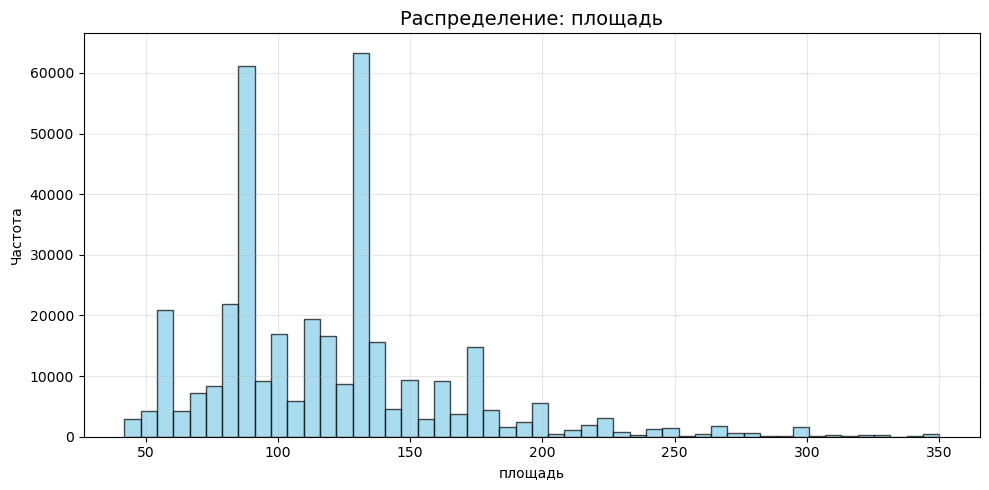

In [5]:
col = 'площадь'
q1 = df[col].quantile(0.01)
q99 = df[col].quantile(0.99)
data = df[col].dropna()
data = data[(data >= q1) & (data <= q99)]

plt.figure(figsize=(10, 5))
plt.hist(data, bins=50, edgecolor='black', alpha=0.7, color='skyblue')
plt.title(f'Распределение: {col}', fontsize=14)
plt.xlabel(col)
plt.ylabel('Частота')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Наиболее распростарененная площать 80-120 кв метров

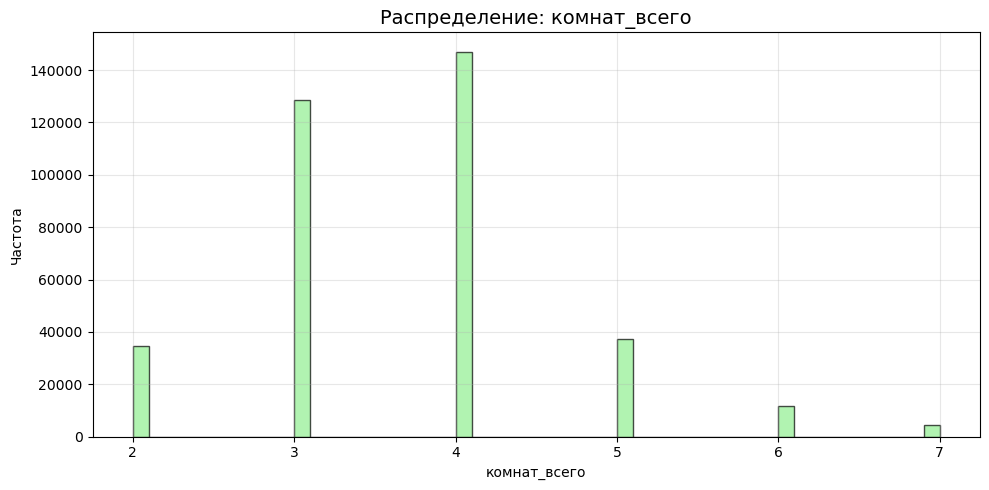

In [6]:
col = 'комнат_всего'
q1 = df[col].quantile(0.01)
q99 = df[col].quantile(0.99)
data = df[col].dropna()
data = data[(data >= q1) & (data <= q99)]

plt.figure(figsize=(10, 5))
plt.hist(data, bins=50, edgecolor='black', alpha=0.7, color='lightgreen')
plt.title(f'Распределение: {col}', fontsize=14)
plt.xlabel(col)
plt.ylabel('Частота')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

чаще всего встречаются дома с 4 комнатами

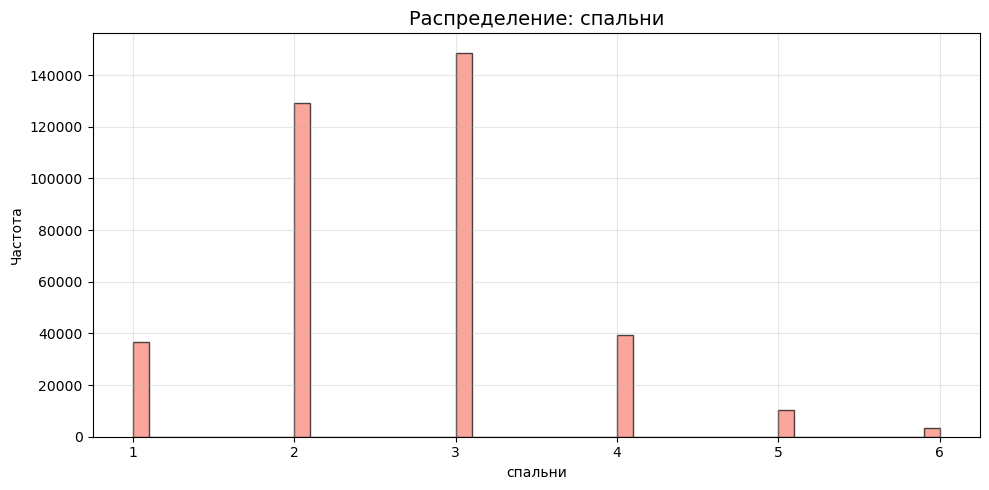

In [7]:
col = 'спальни'
q1 = df[col].quantile(0.01)
q99 = df[col].quantile(0.99)
data = df[col].dropna()
data = data[(data >= q1) & (data <= q99)]

plt.figure(figsize=(10, 5))
plt.hist(data, bins=50, edgecolor='black', alpha=0.7, color='salmon')
plt.title(f'Распределение: {col}', fontsize=14)
plt.xlabel(col)
plt.ylabel('Частота')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

среденее количество спален 3

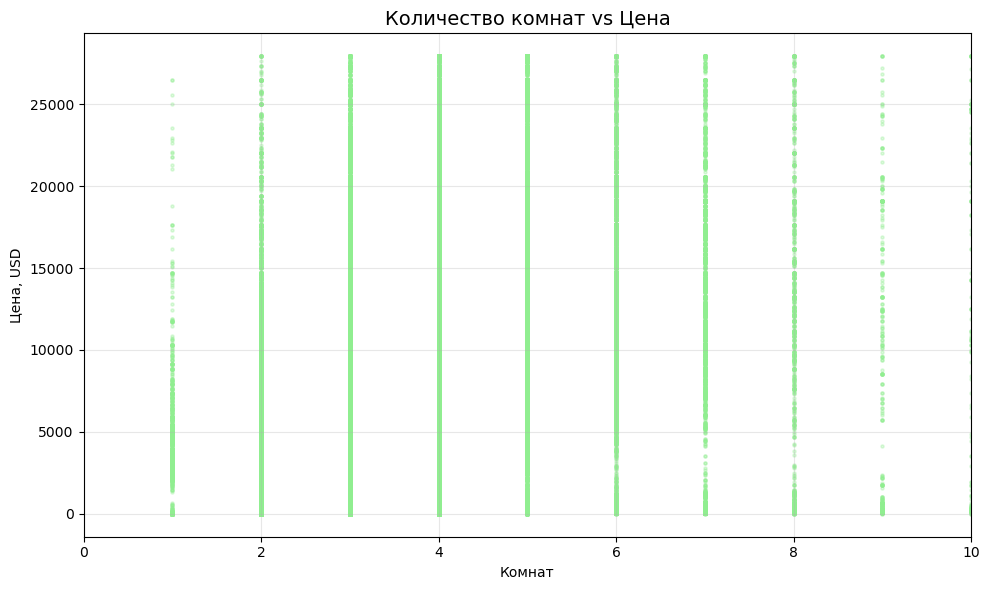

In [12]:
data = df[df['цена_usd'] <= df['цена_usd'].quantile(0.95)]

plt.figure(figsize=(10, 6))
plt.scatter(data['комнат_всего'], data['цена_usd'], alpha=0.3, s=5, color='lightgreen')
plt.title('Количество комнат vs Цена', fontsize=14)
plt.xlabel('Комнат')
plt.ylabel('Цена, USD')
plt.xlim(0, 10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

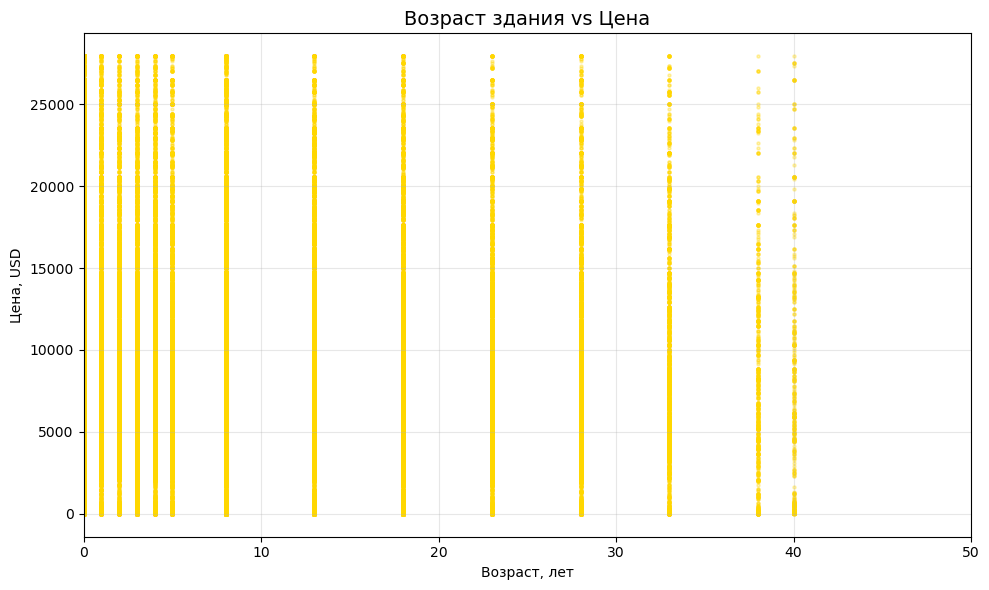

In [13]:
data = df[df['цена_usd'] <= df['цена_usd'].quantile(0.95)]

plt.figure(figsize=(10, 6))
plt.scatter(data['возраст_здания'], data['цена_usd'], alpha=0.3, s=5, color='gold')
plt.title('Возраст здания vs Цена', fontsize=14)
plt.xlabel('Возраст, лет')
plt.ylabel('Цена, USD')
plt.xlim(0, 50)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Чем старше здание тем ниже цена


 КОРРЕЛЯЦИЯ (ПРОДАЖА):
цена_usd          1.000000
площадь           0.461211
комнат_всего      0.407781
спальни           0.397989
гостиные          0.229049
этаж              0.053258
возраст_здания    0.048903
всего_этажей      0.015860
Name: цена_usd, dtype: float64

 КОРРЕЛЯЦИЯ (АРЕНДА):
цена_usd          1.000000
этаж              0.219255
всего_этажей      0.209462
гостиные         -0.123244
возраст_здания   -0.148089
комнат_всего     -0.256081
спальни          -0.268500
площадь          -0.311942
Name: цена_usd, dtype: float64


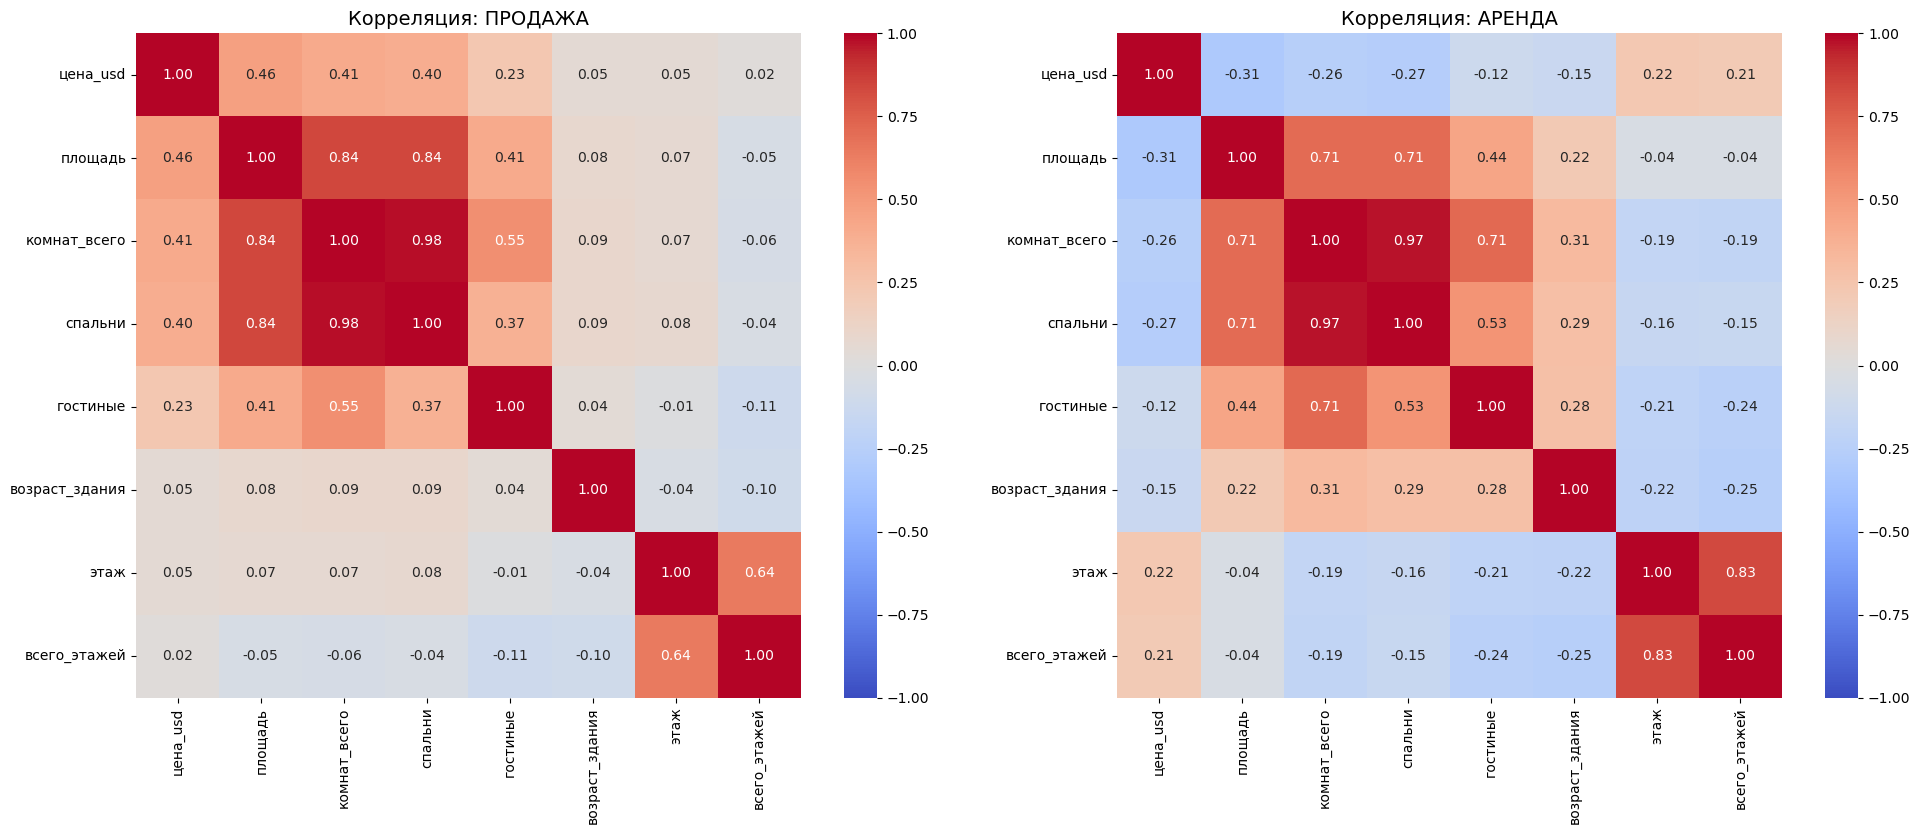

In [31]:
 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = df[
    (df['площадь'] >= 20) &
    (df['площадь'] <= 500) &
    (df['цена_usd'] > 1000)
]

suspicious_sizes = [130, 90, 100, 120, 110, 177, 56, 80, 85]
df = df[~df['площадь'].isin(suspicious_sizes)]


df_sale = df[df['тип_объявления'] == 'Продажа'].copy()
df_rent = df[df['тип_объявления'] == 'Аренда'].copy()

df_sale = df_sale[df_sale['цена_usd'] <= df_sale['цена_usd'].quantile(0.99)]
df_rent = df_rent[df_rent['цена_usd'] <= df_rent['цена_usd'].quantile(0.99)]

numeric_cols = ['цена_usd', 'площадь', 'комнат_всего', 'спальни', 
                'гостиные', 'возраст_здания', 'этаж', 'всего_этажей']

corr_sale = df_sale[numeric_cols].corr()
corr_rent = df_rent[numeric_cols].corr()

print("\n КОРРЕЛЯЦИЯ (ПРОДАЖА):")
print(corr_sale['цена_usd'].sort_values(ascending=False))

print("\n КОРРЕЛЯЦИЯ (АРЕНДА):")
print(corr_rent['цена_usd'].sort_values(ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(corr_sale, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Корреляция: ПРОДАЖА', fontsize=14)

sns.heatmap(corr_rent, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, square=True, ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Корреляция: АРЕНДА', fontsize=14)

plt.tight_layout()
plt.show()

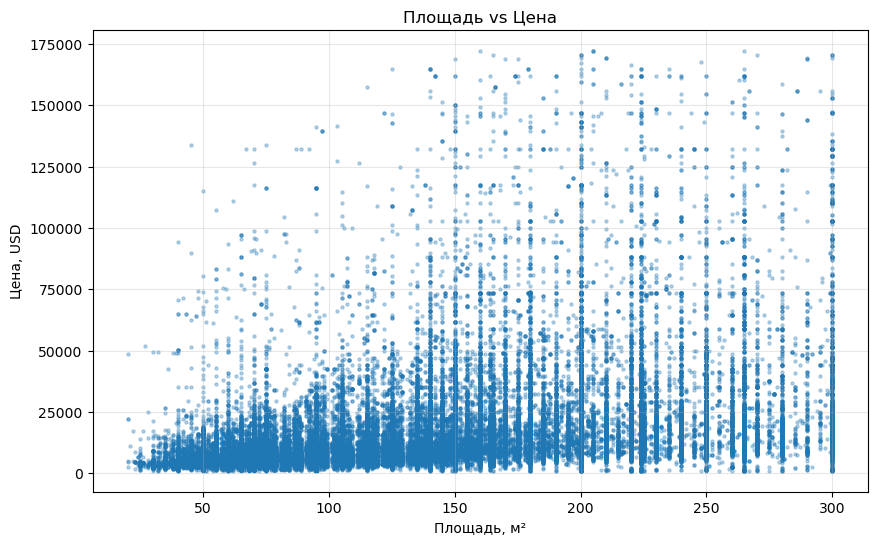

In [33]:
df_plot = df[
    (~df['площадь'].isin([130, 90, 100, 120, 110])) &
    (df['площадь'] >= 20) &
    (df['площадь'] <= 300) &
    (df['цена_usd'] > 1000) &
    (df['цена_usd'] <= df['цена_usd'].quantile(0.99))
]

plt.figure(figsize=(10, 6))
plt.scatter(df_plot['площадь'], df_plot['цена_usd'], alpha=0.3, s=5)
plt.xlabel('Площадь, м²')
plt.ylabel('Цена, USD')
plt.title('Площадь vs Цена')
plt.grid(alpha=0.3)
plt.show()

есть кореляция между ценой площадью

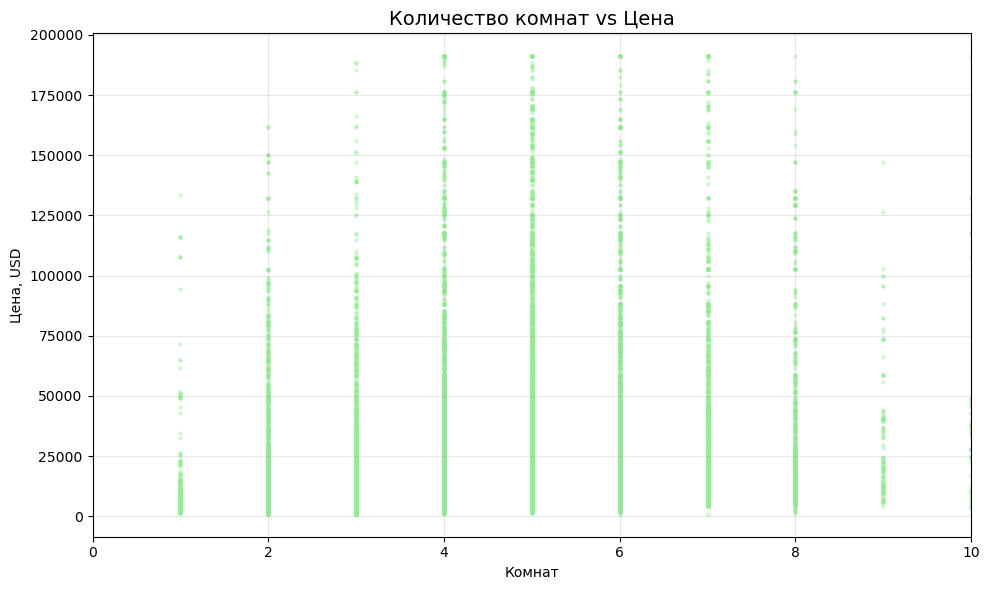

 Корреляция: 0.363


In [38]:
plt.figure(figsize=(10, 6))
plt.scatter(df_sale['комнат_всего'], df_sale['цена_usd'], 
            alpha=0.3, s=5, color='lightgreen')
plt.title('Количество комнат vs Цена', fontsize=14)
plt.xlabel('Комнат')
plt.ylabel('Цена, USD')
plt.xlim(0, 10)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr = df_sale[['комнат_всего', 'цена_usd']].corr().iloc[0, 1]
print(f" Корреляция: {corr:.3f}")

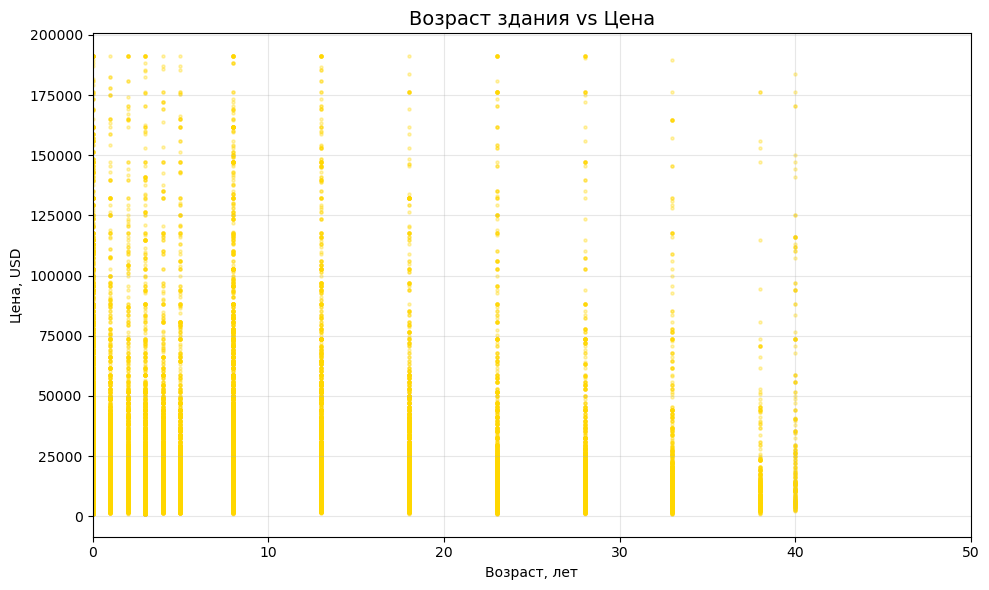

Корреляция: 0.042


In [40]:
plt.figure(figsize=(10, 6))
plt.scatter(df_sale['возраст_здания'], df_sale['цена_usd'], 
            alpha=0.3, s=5, color='gold')
plt.title('Возраст здания vs Цена', fontsize=14)
plt.xlabel('Возраст, лет')
plt.ylabel('Цена, USD')
plt.xlim(0, 50)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr = df_sale[['возраст_здания', 'цена_usd']].corr().iloc[0, 1]
print(f"Корреляция: {corr:.3f}")

нет сильной корреляции между возрастом здания и ценой

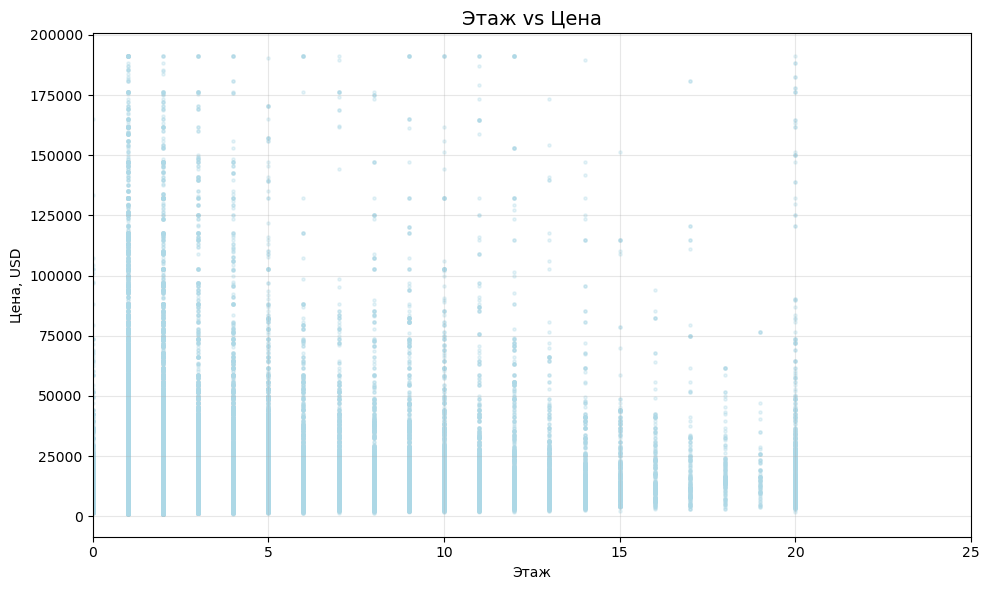

 Корреляция: 0.089


In [41]:
plt.figure(figsize=(10, 6))
plt.scatter(df_sale['этаж'], df_sale['цена_usd'], 
            alpha=0.3, s=5, color='lightblue')
plt.title('Этаж vs Цена', fontsize=14)
plt.xlabel('Этаж')
plt.ylabel('Цена, USD')
plt.xlim(0, 25)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr = df_sale[['этаж', 'цена_usd']].corr().iloc[0, 1]
print(f" Корреляция: {corr:.3f}")

этаж не сильно влияет на цену

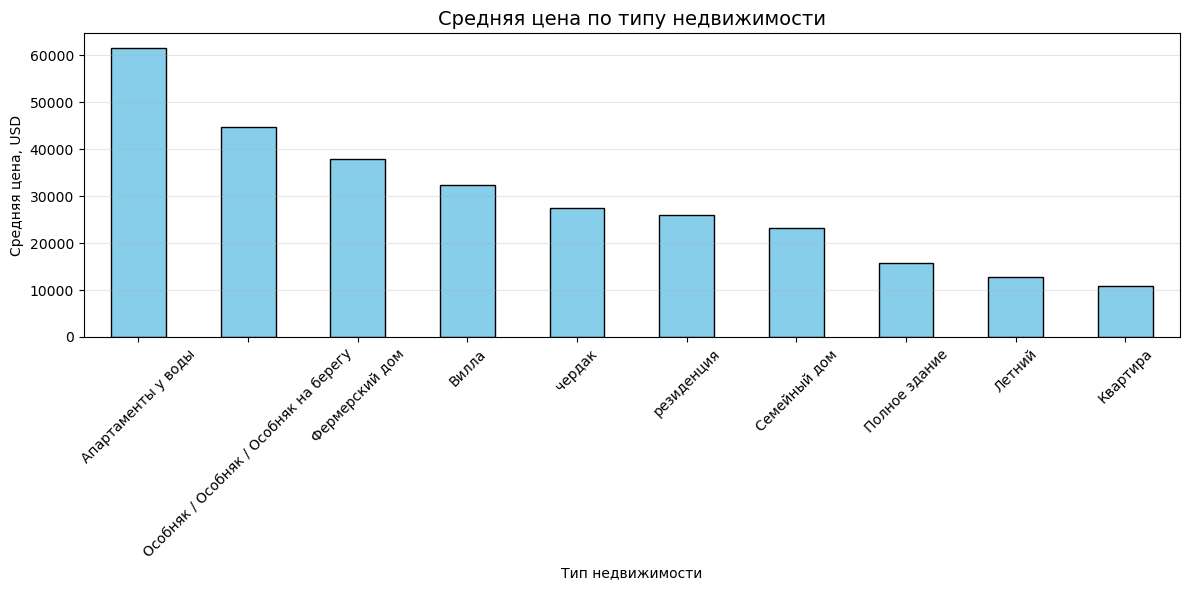

 СРЕДНЯЯ ЦЕНА ПО ТИПУ:
подтип
Апартаменты у воды                       61632.992391
Особняк / Особняк / Особняк на берегу    44791.667167
Фермерский дом                           37994.262822
Вилла                                    32338.611690
чердак                                   27481.618750
резиденция                               25904.248053
Семейный дом                             23311.304441
Полное здание                            15763.338368
Летний                                   12793.581529
Квартира                                 10752.135426
Name: цена_usd, dtype: float64


In [42]:
plt.figure(figsize=(12, 6))

type_price = df_sale.groupby('подтип')['цена_usd'].mean().sort_values(ascending=False).head(10)

type_price.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Средняя цена по типу недвижимости', fontsize=14)
plt.xlabel('Тип недвижимости')
plt.ylabel('Средняя цена, USD')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(" СРЕДНЯЯ ЦЕНА ПО ТИПУ:")
print(type_price)

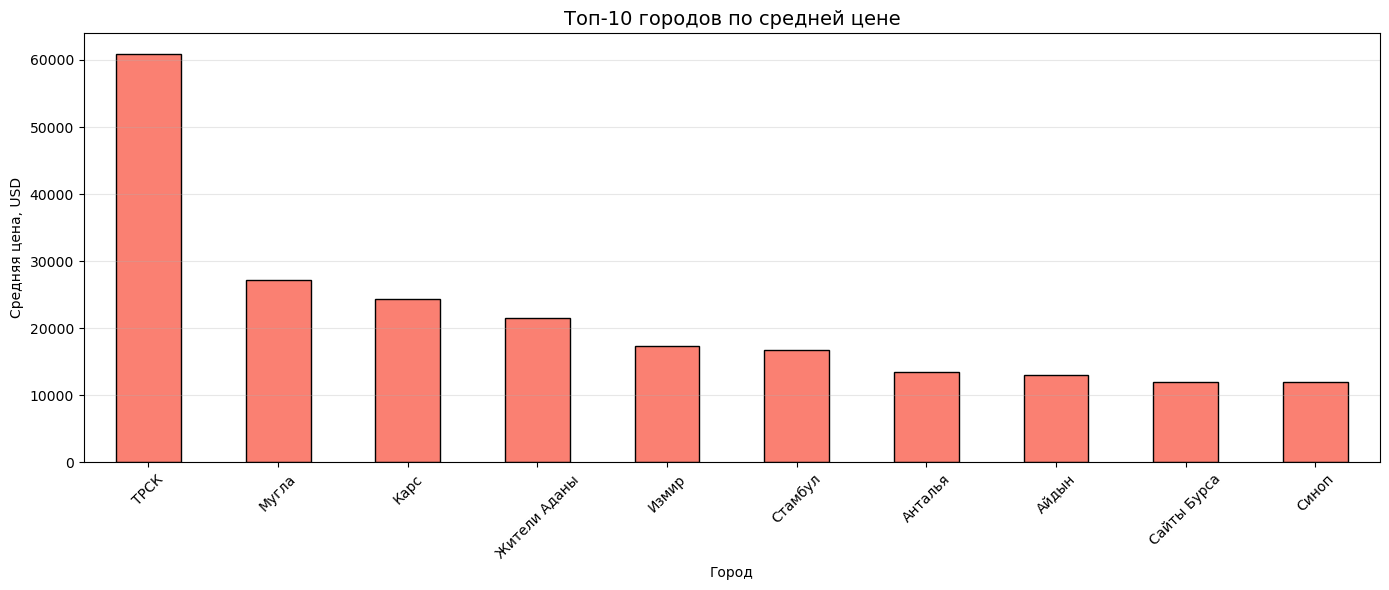

 ТОП-10 ГОРОДОВ ПО ЦЕНЕ:
город
ТРСК            60923.233478
Мугла           27171.754036
Карс            24374.775000
Жители Аданы    21599.673056
Измир           17404.953574
Стамбул         16799.443062
Анталья         13467.543263
Айдын           13102.886498
Сайты Бурса     11964.443433
Синоп           11922.220889
Name: цена_usd, dtype: float64


In [43]:
plt.figure(figsize=(14, 6))

city_price = df_sale.groupby('город')['цена_usd'].mean().sort_values(ascending=False).head(10)

city_price.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Топ-10 городов по средней цене', fontsize=14)
plt.xlabel('Город')
plt.ylabel('Средняя цена, USD')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
print(" ТОП-10 ГОРОДОВ ПО ЦЕНЕ:")
print(city_price)

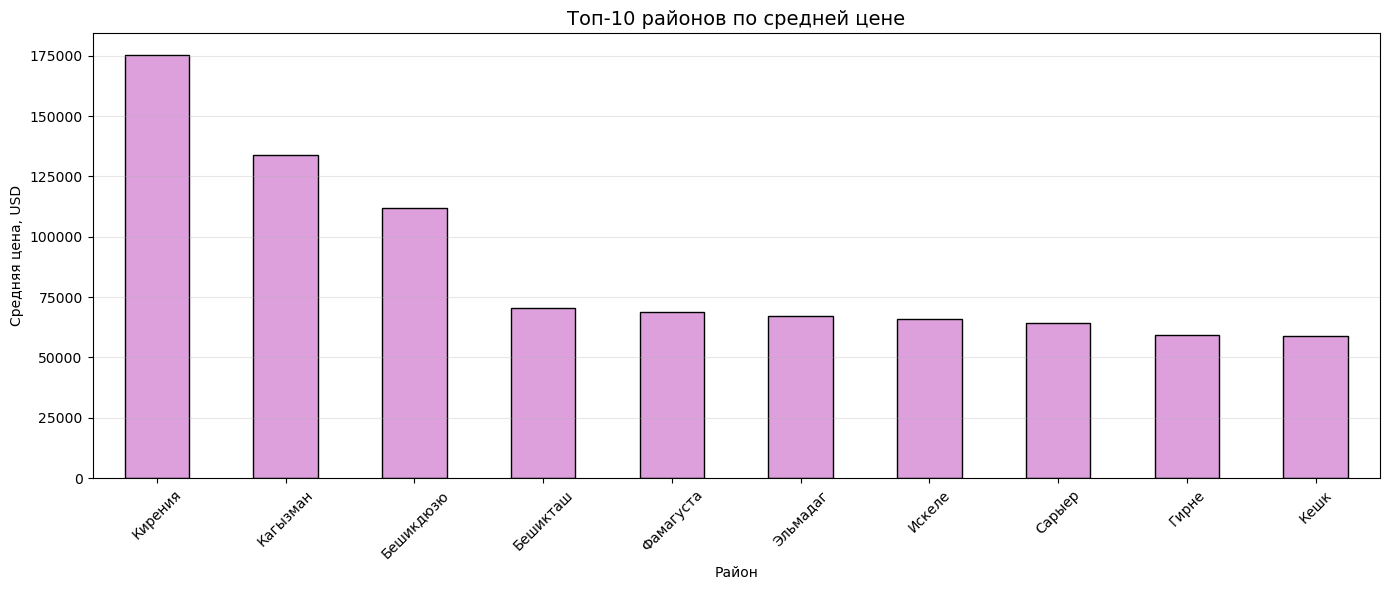

 ТОП-10 РАЙОНОВ ПО ЦЕНЕ:
район
Кирения      175500.000000
Кагызман     133689.820000
Бешикдюзю    111764.710000
Бешикташ      70389.688475
Фамагуста     68795.171385
Эльмадаг      67248.160000
Искеле        66038.538333
Сарыер        64080.839045
Гирне         59227.038136
Кешк          58823.530000
Name: цена_usd, dtype: float64


In [44]:
plt.figure(figsize=(14, 6))

district_price = df_sale.groupby('район')['цена_usd'].mean().sort_values(ascending=False).head(10)

district_price.plot(kind='bar', color='plum', edgecolor='black')
plt.title('Топ-10 районов по средней цене', fontsize=14)
plt.xlabel('Район')
plt.ylabel('Средняя цена, USD')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(" ТОП-10 РАЙОНОВ ПО ЦЕНЕ:")
print(district_price)

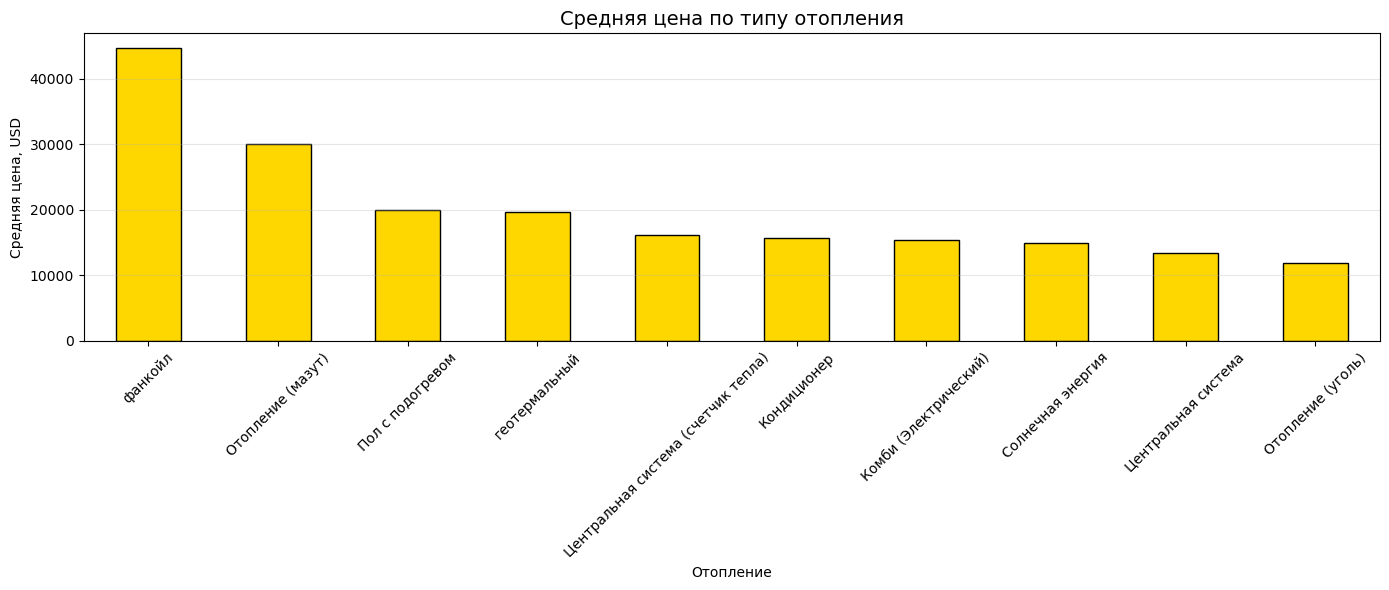

 СРЕДНЯЯ ЦЕНА ПО ОТОПЛЕНИЮ:
отопление
фанкойл                                44735.529545
Отопление (мазут)                      30132.859828
Пол с подогревом                       19979.836917
геотермальный                          19694.200203
Центральная система (счетчик тепла)    16193.336643
Кондиционер                            15733.300422
Комби (Электрический)                  15367.824827
Солнечная энергия                      15022.468050
Центральная система                    13374.610477
Отопление (уголь)                      11922.416881
Name: цена_usd, dtype: float64


In [45]:
plt.figure(figsize=(14, 6))

heating_price = df_sale.groupby('отопление')['цена_usd'].mean().sort_values(ascending=False).head(10)

heating_price.plot(kind='bar', color='gold', edgecolor='black')
plt.title('Средняя цена по типу отопления', fontsize=14)
plt.xlabel('Отопление')
plt.ylabel('Средняя цена, USD')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print(" СРЕДНЯЯ ЦЕНА ПО ОТОПЛЕНИЮ:")
print(heating_price)

#### Логарифмируем цену
Продажа и аренда отличаются по цене на порядки. Логарифм (`log1p`) сглаживает эту разницу, и ошибка модели в логарифмической шкале становится ближе к ошибке в процентах - это помогает снизить MAPE.

In [19]:
print('Цена <= 0:', (df['цена_usd'] <= 0).sum())
df = df[df['цена_usd'] > 0].copy()

df['цена_usd_log'] = np.log1p(df['цена_usd'])

print(f"Асимметрия цены до логарифмирования: {skew(df['цена_usd']):.2f}")
print(f"Асимметрия цены после log1p:         {skew(df['цена_usd_log']):.2f}")

Цена <= 0: 0
Асимметрия цены до логарифмирования: 5.21
Асимметрия цены после log1p:         -0.82


Смотрим, сколько уникальных значений в каждой категориальной колонке - от этого зависит способ кодирования.

In [20]:
cat_cols = ['тип', 'подтип', 'тип_объявления', 'отопление', 'валюта', 'город', 'район', 'улица']
cat_cols = [c for c in cat_cols if c in df.columns]

for col in cat_cols:
    print(f'{col:20s} -> {df[col].nunique()} уникальных значений')

тип                  -> 1 уникальных значений
подтип               -> 12 уникальных значений
тип_объявления       -> 2 уникальных значений


отопление            -> 15 уникальных значений
валюта               -> 4 уникальных значений
город                -> 97 уникальных значений
район                -> 586 уникальных значений
улица                -> 4631 уникальных значений


In [21]:
CARDINALITY_THRESHOLD = 20

ohe_cols = [c for c in cat_cols if df[c].nunique() <= CARDINALITY_THRESHOLD]
target_enc_cols = [c for c in cat_cols if df[c].nunique() > CARDINALITY_THRESHOLD]

print('One-Hot Encoding применим к:', ohe_cols)
print('Целевое кодирование применим к:', target_enc_cols)

One-Hot Encoding применим к: ['тип', 'подтип', 'тип_объявления', 'отопление', 'валюта']
Целевое кодирование применим к: ['город', 'район', 'улица']


In [22]:
df = pd.get_dummies(df, columns=ohe_cols, drop_first=True, dtype=int)
print('Размерность после One-Hot Encoding:', df.shape)

Размерность после One-Hot Encoding: (369746, 43)


In [23]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', train_df.shape, ' Test:', test_df.shape)

Train: (295796, 43)  Test: (73950, 43)


#### Целевое кодирование район/город/улица
У этих признаков слишком много уникальных значений для One-Hot Encoding. Заменяем каждую категорию на среднюю цену объектов в ней (кодирование обучаем только на train, чтобы не было утечки данных). Сглаживание (`MIN_SAMPLES`) не даёт редким категориям получить ненадёжное среднее.

In [24]:
global_mean = train_df['цена_usd_log'].mean()


In [25]:
MIN_SAMPLES = 50

In [26]:
def target_encode(train_df, test_df, col, target='цена_usd_log'):
    means = train_df.groupby(col)[target].mean()
    counts = train_df.groupby(col)[target].count()
    smoothed = (means * counts + global_mean * MIN_SAMPLES) / (counts + MIN_SAMPLES)
    train_enc = train_df[col].map(smoothed)
    test_enc = test_df[col].map(smoothed).fillna(global_mean)
    return train_enc, test_enc, smoothed

In [27]:
encoding_maps = {}
for col in target_enc_cols:
    train_unique = set(train_df[col].unique())
    test_unique = set(test_df[col].unique())
    unseen = test_unique - train_unique
    print(f"{col}: {len(unseen)} новых категорий из {len(test_unique)} в test "
          f"({len(unseen) / len(test_unique) * 100:.1f}%) получат глобальное среднее")

    train_df[col + '_te'], test_df[col + '_te'], enc_map = target_encode(train_df, test_df, col)
    encoding_maps[col] = enc_map

город: 2 новых категорий из 89 в test (2.2%) получат глобальное среднее
район: 21 новых категорий из 452 в test (4.6%) получат глобальное среднее
улица: 174 новых категорий из 3335 в test (5.2%) получат глобальное среднее


In [28]:
train_df = train_df.drop(columns=target_enc_cols)
test_df = test_df.drop(columns=target_enc_cols)

In [29]:
print('\nДобавлены закодированные колонки:', [c + '_te' for c in target_enc_cols])


Добавлены закодированные колонки: ['город_te', 'район_te', 'улица_te']


In [30]:
leak_cols = ['цена_usd', 'цена_usd_log']

X_train = train_df.drop(columns=leak_cols)
y_train = train_df['цена_usd_log']
X_test = test_df.drop(columns=leak_cols)
y_test = test_df['цена_usd_log']

print(f'X_train: {X_train.shape}, X_test: {X_test.shape}')
print(f'Количество признаков: {X_train.shape[1]}')

X_train: (295796, 41), X_test: (73950, 41)
Количество признаков: 41


GridSearchCV ищет параметры на части train (60%), а финальная модель обучается уже на всех данных - так быстрее.

In [31]:
SAMPLE_FRAC = 0.6  
sample_index = X_train.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).index
X_train_search = X_train.loc[sample_index]
y_train_search = y_train.loc[sample_index]

#### Функции для оценки моделей
`evaluate_model` считает метрики (MAE, RMSE, MAPE, R²) в долларах, `check_overfitting` сравнивает качество на train и test.

In [32]:
def evaluate_model(model, X_train, y_train, X_test, y_test, name):
    model.fit(X_train, y_train)
    pred_log = model.predict(X_test)

    y_test_usd = np.expm1(y_test)
    pred_usd = np.expm1(pred_log)

    mae = mean_absolute_error(y_test_usd, pred_usd)
    rmse = np.sqrt(mean_squared_error(y_test_usd, pred_usd))
    mape = mean_absolute_percentage_error(y_test_usd, pred_usd) * 100
    r2 = r2_score(y_test_usd, pred_usd)

    metrics = {'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}
    print(f'{name}:')
    print(f'  MAE  = {mae:,.0f} $')
    print(f'  RMSE = {rmse:,.0f} $')
    print(f'  MAPE = {mape:.2f} %')
    print(f'  R2   = {r2:.4f}')
    return metrics, model, pred_usd

In [33]:
def check_overfitting(model, X_train, y_train, X_test, y_test, name):
    pred_train_usd = np.expm1(model.predict(X_train))
    pred_test_usd = np.expm1(model.predict(X_test))
    y_train_usd = np.expm1(y_train)
    y_test_usd = np.expm1(y_test)

    mape_train = mean_absolute_percentage_error(y_train_usd, pred_train_usd) * 100
    mape_test = mean_absolute_percentage_error(y_test_usd, pred_test_usd) * 100
    r2_train = r2_score(y_train_usd, pred_train_usd)
    r2_test = r2_score(y_test_usd, pred_test_usd)

    print(f'{name}: MAPE train={mape_train:.2f}% / test={mape_test:.2f}%  |  '
          f'R2 train={r2_train:.4f} / test={r2_test:.4f}')
    gap = mape_test - mape_train
    if gap > 5:
        print(f'Разрыв MAPE {gap:.1f} п.п. — похоже на переобучение, стоит увеличить MIN_SAMPLES '
              f'или ограничить глубину/min_samples_leaf модели')
    else:
        print('Разрыв между train и test небольшой, переобучение не выражено')

## DecisionTreeRegressor

Сначала baseline с параметрами по умолчанию, затем подбор гиперпараметров через `GridSearchCV`, затем проверка на переобучение, как и требовалось в постановке задачи.

In [34]:
dt_base = DecisionTreeRegressor(random_state=RANDOM_STATE)
metrics_dt_base, _, _ = evaluate_model(dt_base, X_train, y_train, X_test, y_test, 'Decision Tree (baseline)')

Decision Tree (baseline):
  MAE  = 2,051 $
  RMSE = 7,697 $
  MAPE = 27.53 %
  R2   = 0.7559


In [35]:
dt_grid = {
    'max_depth': [8, 12, 16, 20],
    'min_samples_leaf': [10, 20]
}

dt_search = GridSearchCV(
    DecisionTreeRegressor(random_state=RANDOM_STATE),
    dt_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1
)
dt_search.fit(X_train_search, y_train_search)
print('Лучшие параметры:', dt_search.best_params_)

Лучшие параметры: {'max_depth': 20, 'min_samples_leaf': 10}


In [36]:
best_dt = DecisionTreeRegressor(**dt_search.best_params_, random_state=RANDOM_STATE)
metrics_dt, dt_model, pred_dt = evaluate_model(best_dt, X_train, y_train, X_test, y_test, 'Decision Tree (tuned)')

Decision Tree (tuned):
  MAE  = 2,420 $
  RMSE = 7,439 $
  MAPE = 26.37 %
  R2   = 0.7720


In [37]:
check_overfitting(dt_model, X_train, y_train, X_test, y_test, 'Decision Tree')

Decision Tree: MAPE train=21.55% / test=26.37%  |  R2 train=0.8298 / test=0.7720
Разрыв между train и test небольшой, переобучение не выражено


## RandomForestRegressor

In [38]:
rf_base = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
metrics_rf_base, _, _ = evaluate_model(rf_base, X_train, y_train, X_test, y_test, 'Random Forest (baseline)')

Random Forest (baseline):
  MAE  = 1,734 $
  RMSE = 5,902 $
  MAPE = 19.17 %
  R2   = 0.8564


In [39]:
rf_grid = {
    'n_estimators': [100, 150],
    'max_depth': [12, 18, None],
    'min_samples_leaf': [5, 10]
}

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    rf_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1
)
rf_search.fit(X_train_search, y_train_search)
print('Лучшие параметры:', rf_search.best_params_)

Лучшие параметры: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 150}


In [40]:
best_rf = RandomForestRegressor(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
metrics_rf, rf_model, pred_rf = evaluate_model(best_rf, X_train, y_train, X_test, y_test, 'Random Forest (tuned)')

Random Forest (tuned):
  MAE  = 2,004 $
  RMSE = 6,539 $
  MAPE = 21.10 %
  R2   = 0.8238


In [41]:
check_overfitting(rf_model, X_train, y_train, X_test, y_test, 'Random Forest')

Random Forest: MAPE train=15.04% / test=21.10%  |  R2 train=0.8832 / test=0.8238
Разрыв MAPE 6.1 п.п. — похоже на переобучение, стоит увеличить MIN_SAMPLES или ограничить глубину/min_samples_leaf модели


## HistGradientBoostingRegressor

In [42]:
hgb_base = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
metrics_hgb_base, _, _ = evaluate_model(hgb_base, X_train, y_train, X_test, y_test, 'Gradient Boosting (baseline)')

Gradient Boosting (baseline):
  MAE  = 2,697 $
  RMSE = 8,033 $
  MAPE = 28.29 %
  R2   = 0.7341


In [43]:
hgb_grid = {
    'max_iter': [300, 500],
    'max_depth': [6, 10, None],
    'learning_rate': [0.02, 0.05, 0.1]
}

hgb_estimator = HistGradientBoostingRegressor(
    random_state=RANDOM_STATE,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15
)

hgb_search = GridSearchCV(
    hgb_estimator, hgb_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1
)
hgb_search.fit(X_train_search, y_train_search)
print('Лучшие параметры:', hgb_search.best_params_)

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': None, 'max_iter': 500}


In [44]:
best_hgb = HistGradientBoostingRegressor(
    **hgb_search.best_params_, random_state=RANDOM_STATE,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=15
)
metrics_hgb, hgb_model, pred_hgb = evaluate_model(best_hgb, X_train, y_train, X_test, y_test, 'Gradient Boosting (tuned)')

Gradient Boosting (tuned):
  MAE  = 2,339 $
  RMSE = 7,225 $
  MAPE = 24.53 %
  R2   = 0.7849


In [45]:
check_overfitting(hgb_model, X_train, y_train, X_test, y_test, 'Gradient Boosting')

Gradient Boosting: MAPE train=23.46% / test=24.53%  |  R2 train=0.8131 / test=0.7849
Разрыв между train и test небольшой, переобучение не выражено


Собираем метрики всех трёх моделей в одну таблицу и строим график для наглядного сравнения.

In [46]:
all_results = {
    'Decision Tree':  {'m': metrics_dt,  'p': dt_search.best_params_},
    'Random Forest':  {'m': metrics_rf,  'p': rf_search.best_params_},
    'Gradient Boosting': {'m': metrics_hgb, 'p': hgb_search.best_params_},
}

In [47]:
results_df = pd.DataFrame({n: d['m'] for n, d in all_results.items()}).T
results_df.index.name = 'Модель'
results_df['Лучшие параметры'] = [str(all_results[n]['p']) for n in results_df.index]
results_df

,MAE,RMSE,MAPE,R2,Лучшие параметры
Модель,,,,,
Decision Tree,2420.322308,7439.082035,26.373070,0.771955,"{'max_depth': 20, 'min_samples_leaf': 10}"
Random Forest,2003.638081,6538.615404,21.097383,0.823821,"{'max_depth': None, 'min_samples_leaf': 5, 'n_..."
Gradient Boosting,2339.138613,7225.474142,24.526450,0.784863,"{'learning_rate': 0.1, 'max_depth': None, 'max..."


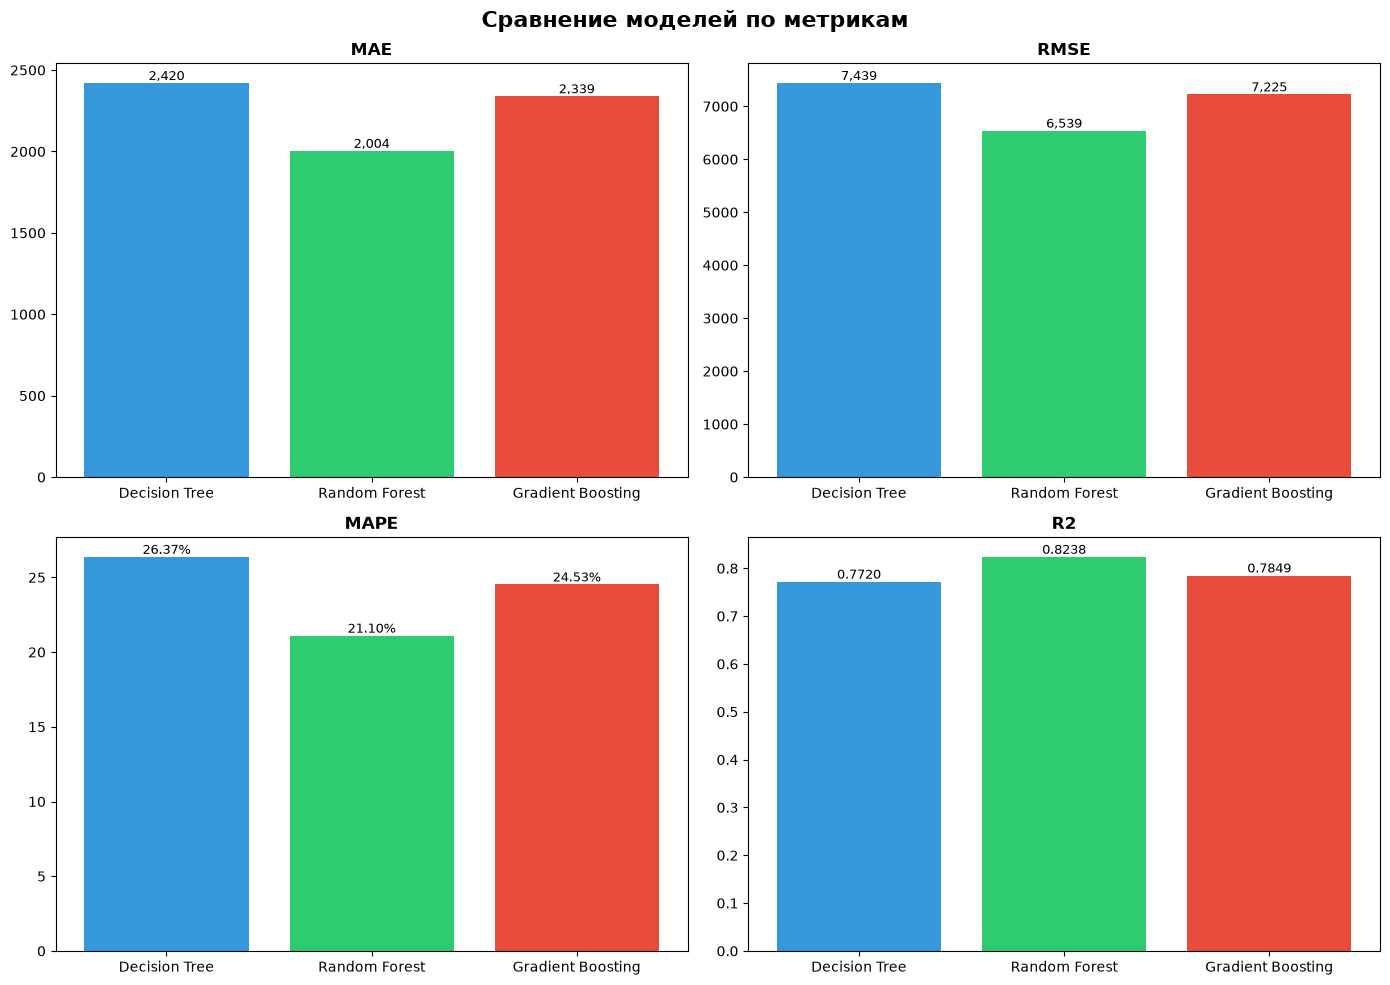

In [48]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Сравнение моделей по метрикам', fontsize=16, fontweight='bold')

colors = ['#3498db', '#2ecc71', '#e74c3c']
names = list(all_results.keys())

for ax, metric in zip(axes.flatten(), ['MAE', 'RMSE', 'MAPE', 'R2']):
    vals = [all_results[n]['m'][metric] for n in names]
    bars = ax.bar(names, vals, color=colors)
    ax.set_title(metric, fontweight='bold')
    for b, v in zip(bars, vals):
        fmt = f'{v:.4f}' if metric == 'R2' else f'{v:,.0f}' if metric != 'MAPE' else f'{v:.2f}%'
        ax.text(b.get_x() + b.get_width()/2, b.get_height(), fmt, ha='center', va='bottom', fontsize=9)
    
plt.tight_layout()
plt.show()

Выбираем модель с лучшим R², смотрим на график "прогноз vs факт", остатки и важность признаков.

In [49]:
best_name = max(all_results, key=lambda k: all_results[k]['m']['R2'])
best_model = {'Decision Tree': dt_model, 'Random Forest': rf_model, 'Gradient Boosting': hgb_model}[best_name]
best_pred_usd = {'Decision Tree': pred_dt, 'Random Forest': pred_rf, 'Gradient Boosting': pred_hgb}[best_name]
y_test_usd = np.expm1(y_test)

print(f'Лучшая модель: {best_name} (R2={all_results[best_name]["m"]["R2"]:.4f})')

Лучшая модель: Random Forest (R2=0.8238)


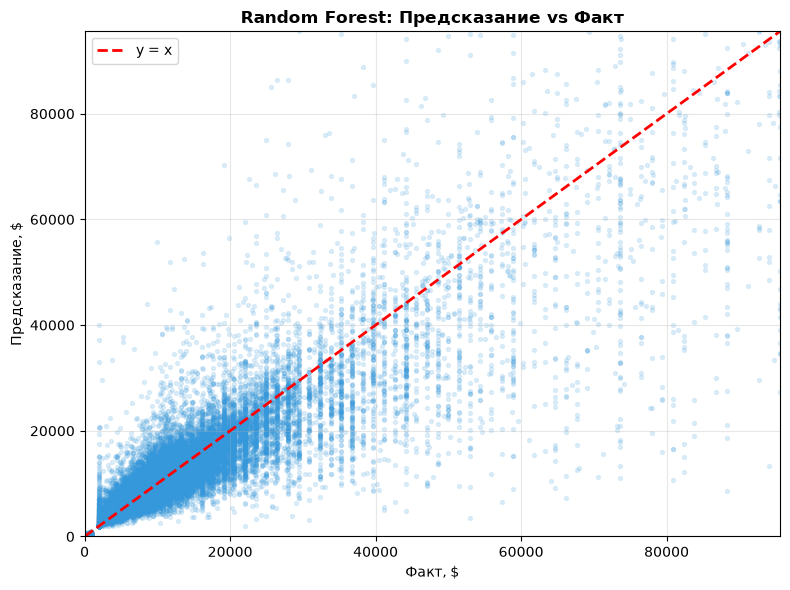

In [50]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test_usd, best_pred_usd, alpha=0.15, s=8, color='#3498db')
lims = [0, y_test_usd.quantile(0.99)]
plt.plot(lims, lims, 'r--', lw=2, label='y = x')
plt.xlim(lims); plt.ylim(lims)
plt.xlabel('Факт, $'); plt.ylabel('Предсказание, $')
plt.title(f'{best_name}: Предсказание vs Факт', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

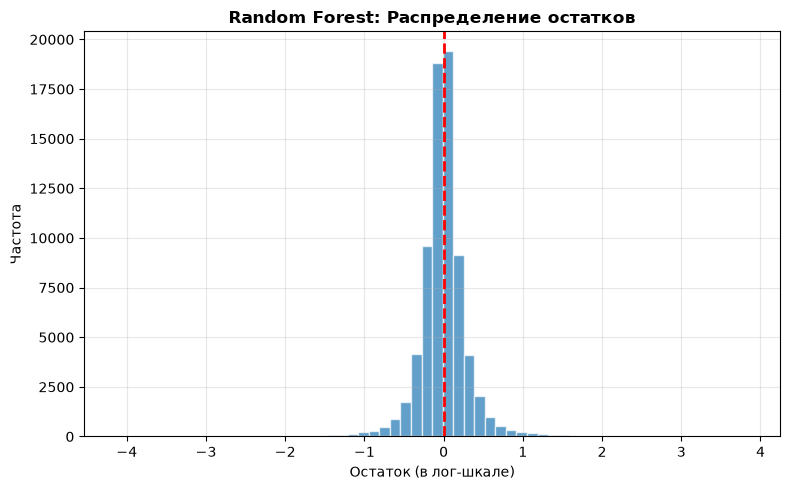

In [51]:
residuals = y_test.values - np.log1p(best_pred_usd)
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=60, alpha=0.7, edgecolor='white')
plt.axvline(0, color='red', ls='--', lw=2)
plt.xlabel('Остаток (в лог-шкале)'); plt.ylabel('Частота')
plt.title(f'{best_name}: Распределение остатков', fontweight='bold')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

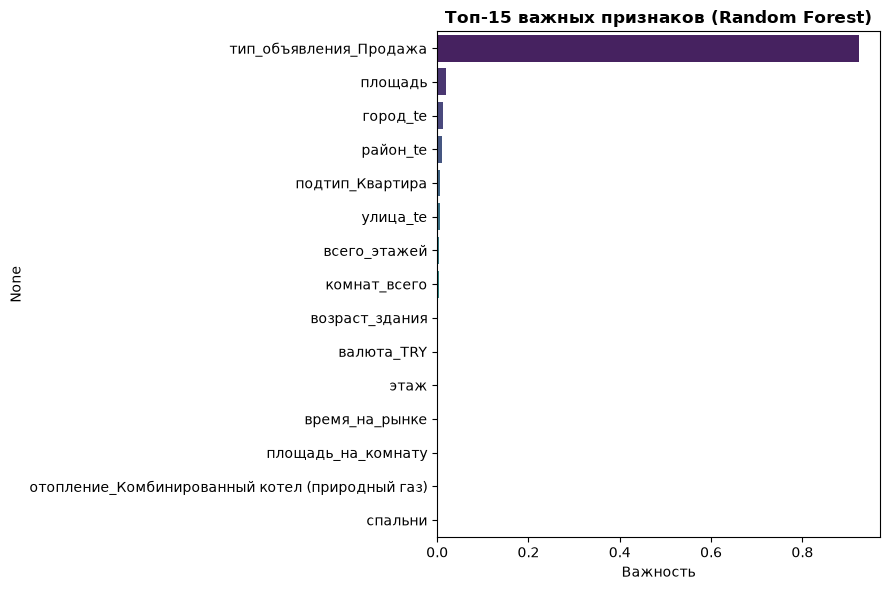

In [52]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title(f'Топ-15 важных признаков ({best_name})', fontweight='bold')
plt.xlabel('Важность')
plt.tight_layout(); plt.show()

In [53]:
os.makedirs('models', exist_ok=True)

joblib.dump(best_model, 'models/best_model.pkl')
joblib.dump(encoding_maps, 'models/target_encoding_maps.pkl')
joblib.dump(list(X_train.columns), 'models/feature_columns.pkl')
joblib.dump(ohe_cols, 'models/ohe_columns.pkl')
joblib.dump(global_mean, 'models/global_mean_price.pkl')

['models/global_mean_price.pkl']

# Скриншоты приложения

Общий вид приложения:

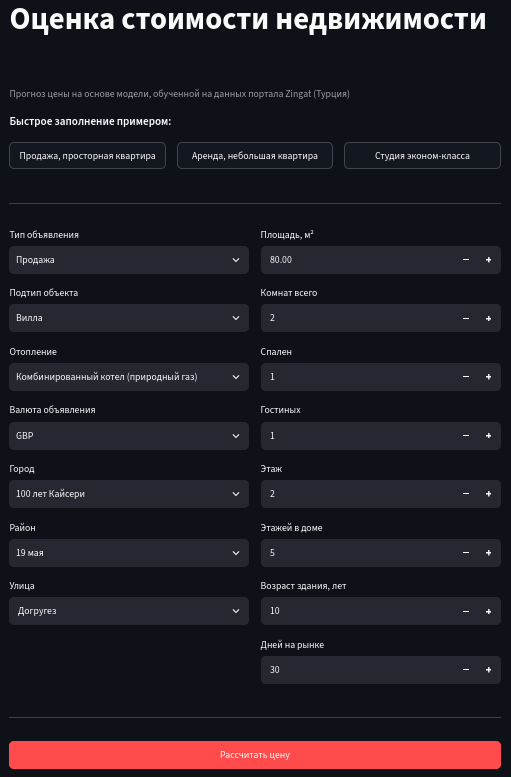

Рассчёт цены (Внизу указывается диапазон цен с учётом MAE):

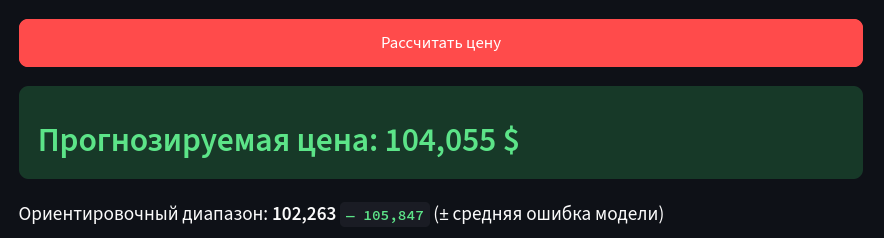

Также в приложении есть небольшая справка:

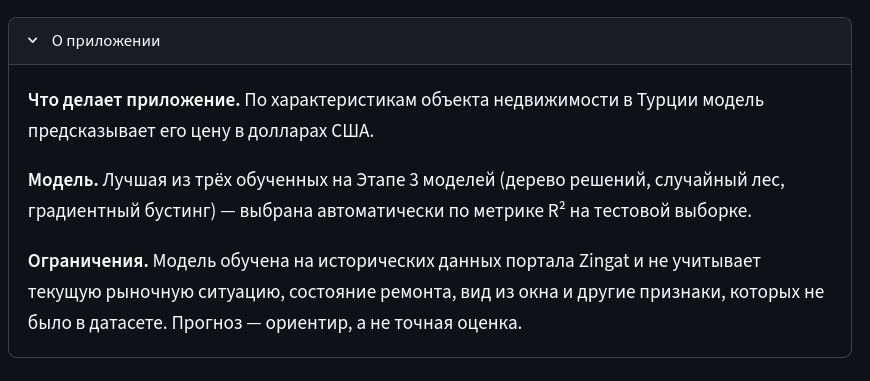

# Ссылка на Дашборд в DataLens

In [ ]:
https://datalens.yandex/noq9ntx9b1lo6?_share_link=public

# Итоговые выводы

**Данные.** Исходный датасет Zingat содержал 403487 объявлений (17 столбцов) о продаже и аренде жилья в Турции. Столбец `furnished` был пуст на 100%, остальные признаки содержали пропуски и значения на турецком языке. После очистки в работе осталось 369746 объектов.

**Подготовка данных.**
- Категориальные признаки переведены на русский язык, адрес разделён на город, район и улицу.
- Возраст здания, этаж и этажность приведены к числам, а комнаты вида «3+1» разложены на спальни, гостиные и общее число комнат.
- Пропуски заполнены логично для каждого признака: возраст здания медианой, отопление самым частым значением в районе, площадь медианой по группе «тип + планировка». Строки с оставшимися пропусками (менее 6%) удалены.
- Цены приведены к USD. Выбросы обрезаны по 1–99 перцентилям отдельно для продажи и аренды, площадь ограничена диапазоном 42–350 м².
- Добавлен признак «площадь на комнату», целевая переменная прологарифмирована (асимметрия цены снизилась с 5.21 до −0.82).

**Разведочный анализ.**
- Продажа и аренда отличаются по цене на два порядка: после очистки медиана составляет около 7941$ для продажи и 35$ для аренды. Поэтому тип объявления оказался ключевым признаком.
- Для продажи цена сильнее всего связана с площадью (корреляция 0.46), числом комнат (0.41) и спален (0.40). Этаж (0.05), возраст здания (0.05) и этажность (0.02) почти не влияют.
- В аренде связи слабее, а у числа комнат и спален они даже отрицательные (около −0.26). Вероятно, это отражает структуру предложения: компактные квартиры сдаются чаще, чем большие дома.
- Дороже всего продаются апартаменты у воды, особняки и виллы. В топе средних цен по районам встречаются и малочисленные районы, где высокое среднее может быть случайным, поэтому такие значения нужно трактовать осторожно.

**Моделирование.** Категориальные признаки с небольшим числом значений закодированы One-Hot, а город, район и улица (97, 586 и 4 631 значение) закодированы средней ценой со сглаживанием. Кодирование обучалось только на train, чтобы не допустить утечки данных. Итоговый набор содержит 41 признак, выборка разделена 80/20. Для трёх моделей подбирались гиперпараметры через GridSearchCV:

| Модель | MAE, $ | RMSE, $ | MAPE, % | R² |
|---|---|---|---|---|
| Decision Tree | 2 420 | 7 439 | 26.4 | 0.772 |
| **Random Forest** | **2 004** | **6 539** | **21.1** | **0.824** |
| Gradient Boosting | 2 339 | 7 225 | 24.5 | 0.785 |

Лучшей признана **Random Forest** (R² = 0.82, MAPE около 21%). Она сохранена вместе с таблицами кодирования и использована в приложении.

**Что показала модель.**
- Важность признака «тип объявления = продажа» составляет около 0.92, то есть модель прежде всего отличает продажу от аренды. Высокий R² отчасти объясняется именно этим разрывом в масштабе цен. Следующие по важности признаки: площадь, город, район и подтип объекта.
- Random Forest склонна к переобучению: MAPE на train 15.0% против 21.1% на test. У Gradient Boosting разрыв минимален (23.5% против 24.5%), но он точнее не стал.

**Ограничения.**
- Цены пересчитаны по единому курсу 1 TRY = 1/34 USD, хотя объявления относятся к 2018–2019 годам. Значения в «долларах» условны: они подходят для сравнения объектов между собой, но не отражают реальную стоимость в USD того периода.
- Часть названий переведена автоматическим переводчиком неточно (например, «Жители Аданы» вместо Адана), что вносит шум в категории.
- Заполнение пропусков медианами сглаживает индивидуальные особенности объектов, а редкие дорогие и курортные объекты модель занижает.

**Возможные улучшения.**
- Обучить отдельные модели для продажи и аренды.
- Использовать курс валюты на дату объявления.
- Подобрать гиперпараметры на полной выборке и с другой метрикой. Random Forest с параметрами по умолчанию показала лучшие метрики (MAE 1 734 $, MAPE 19.2%, R² 0.856), чем настроенная версия, значит, подбор на 60% выборки не дал выигрыша.
- Добавить признаки состояния объекта и точных координат.

**Практический результат.** Построено приложение для оценки цены объекта: оно показывает прогноз и диапазон с учётом MAE. Результаты также визуализированы на дашборде DataLens.